# Frozen Bridge sample-retrieval geometry

This is the human-readable Stage 0–1 report for the independent
`sample_retrieval_geometry` benchmark. It loads saved results only: it does not
regenerate embeddings, recompute the 562 × 510,709 search, or train a model.
See `REPORT.md` for equations, detailed provenance, limitations, and the final
recommendation.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

def find_here(start):
    for p in (start.resolve(), *start.resolve().parents):
        c = p if p.name == 'sample_retrieval_geometry' else p / 'benchmarks' / 'sample_retrieval_geometry'
        if (c / 'config.json').is_file(): return c
    raise FileNotFoundError('sample_retrieval_geometry not found')

HERE = find_here(Path.cwd()); RESULTS = HERE / 'results'
comparison = pd.read_csv(RESULTS / 'ranked_method_comparison.csv')
distributions = pd.read_csv(RESULTS / 'cosine_distributions.csv')
density = pd.read_csv(RESULTS / 'density_stratified_metrics.csv')
hubness = pd.read_csv(RESULTS / 'hubness_summary.csv')
set_metrics = pd.read_csv(RESULTS / 'set_retrieval_metrics.csv')
provenance = json.loads((RESULTS / 'provenance.json').read_text())
BIO = RESULTS / 'biological_validation'
composition = pd.read_csv(BIO / 'composition_summary.csv')
label_qc = pd.read_csv(BIO / 'biological_label_summary.csv')
density_models = pd.read_csv(BIO / 'density_failure_models.csv')
source_comparison = pd.read_csv(BIO / 'main_comparison_source_label.csv')
tissue_comparison = pd.read_csv(BIO / 'main_comparison_tissue_label.csv')
set_biology = pd.read_csv(BIO / 'set_method_biological_summary.csv')
diversity = pd.read_csv(BIO / 'retrieval_diversity_summary.csv')
AUDIT = RESULTS / 'recount3_audit'
funnel = pd.read_csv(AUDIT / 'original_cohort_funnel.csv')
macro = pd.read_csv(AUDIT / 'study_macro_retrieval_metrics.csv')
capped = pd.read_csv(AUDIT / 'capped_study_retrieval_metrics.csv')
cohort_inventory = pd.read_csv(AUDIT / 'bridge_evaluation_cohort_inventory.csv')
expansion = pd.read_csv(AUDIT / 'expansion_inventory.csv')
ABS = RESULTS / 'absolute_similarity'
cosine_by_rank = pd.read_csv(ABS / 'exact_pair_cosine_by_rank.csv')
cosine_micro_macro = pd.read_csv(ABS / 'paired_cosine_micro_macro_summary.csv')
expanded_micro = pd.read_csv(ABS / 'expanded_ranked_metrics_micro.csv')
expanded_macro = pd.read_csv(ABS / 'expanded_ranked_metrics_study_macro.csv')
random_exact = pd.read_csv(ABS / 'random_vs_exact_cosine.csv')
random_percentiles = pd.read_csv(ABS / 'exact_cosine_random_empirical_percentiles.csv')
near_counts = pd.read_csv(ABS / 'near_exact_neighbor_counts_by_rank.csv')
poor_rank_frequency = pd.read_csv(ABS / 'high_similarity_poor_rank_frequency.csv')
native_scores = pd.read_csv(ABS / 'method_native_score_by_rank.csv')
poor_rank_examples = pd.read_csv(ABS / 'high_similarity_poor_rank_examples.csv')
ANISO = RESULTS / 'anisotropy'
anisotropy = pd.read_csv(ANISO / 'anisotropy_summary.csv')
pca_summary = pd.read_csv(ANISO / 'pca_summary.csv')
geometry_distributions = pd.read_csv(ANISO / 'cosine_distribution_summaries.csv')
geometry_retrieval = pd.read_csv(ANISO / 'geometry_vs_local_corrections.csv')
geometry_macro = pd.read_csv(ANISO / 'retrieval_metrics_study_macro.csv')
geometry_biology = pd.read_csv(ANISO / 'biological_neighborhood_preservation.csv')
geometry_density = pd.read_csv(ANISO / 'query_density_summary.csv')
geometry_hubness = pd.read_csv(ANISO / 'hubness_summary.csv')
geometry_separation = pd.read_csv(ANISO / 'similarity_separation_metrics.csv')
LIT = RESULTS / 'literature_postprocessing'
literature_main = pd.read_csv(LIT / 'main_comparison.csv')
literature_distributions = pd.read_csv(LIT / 'cosine_distribution_summaries.csv')
literature_diagnostics = pd.read_csv(LIT / 'alignment_uniformity.csv')
literature_macro = pd.read_csv(LIT / 'retrieval_metrics_study_macro.csv')
literature_biology = pd.read_csv(LIT / 'biological_neighborhood_preservation.csv')
literature_hubness = pd.read_csv(LIT / 'hubness_summary.csv')
whitening_diagnostics = pd.read_csv(LIT / 'whitening_diagnostics.csv')
GTEX = RESULTS / 'gtex_biological_retrieval'
gtex_cohort = pd.read_csv(GTEX / 'gtex_cohort_summary.csv')
gtex_annotation = pd.read_csv(GTEX / 'archs4_annotation_summary.csv')
gtex_harmonization = pd.read_csv(GTEX / 'tissue_harmonization.csv')
gtex_micro = pd.read_csv(GTEX / 'retrieval_metrics_micro.csv')
gtex_macro = pd.read_csv(GTEX / 'retrieval_metrics_tissue_macro.csv')
gtex_per_tissue = pd.read_csv(GTEX / 'per_tissue_p10_comparison.csv')
gtex_comparison = pd.read_csv(GTEX / 'technical_identity_vs_biological_retrieval.csv')
gtex_control = pd.read_csv(GTEX / 'gtex_to_gtex_control.csv')
gtex_density = pd.read_csv(GTEX / 'density_by_tissue.csv')
gtex_raw_scores = pd.read_csv(GTEX / 'raw_cosine_by_tissue_match_status.csv')
CTRL = RESULTS / 'representation_metric_controls'
control_assets = json.loads((CTRL / 'asset_audit.json').read_text())
control_micro = pd.read_csv(CTRL / 'micro_metrics.csv')
control_macro = pd.read_csv(CTRL / 'study_macro_metrics.csv')
control_separation = pd.read_csv(CTRL / 'separation_metrics.csv')
control_pca = pd.read_csv(CTRL / 'pca_provenance.csv')
control_sensitivity = pd.read_csv(CTRL / 'metric_sensitivity_summary.csv')
GCTRL = RESULTS / 'gtex_representation_controls'
gctrl_identity = pd.read_csv(GCTRL / 'identity_vs_biological_retrieval.csv')
gctrl_micro = pd.read_csv(GCTRL / 'retrieval_metrics_micro.csv')
gctrl_macro = pd.read_csv(GCTRL / 'retrieval_metrics_tissue_macro.csv')
gctrl_tissue = pd.read_csv(GCTRL / 'per_tissue_metrics.csv')
gctrl_control = pd.read_csv(GCTRL / 'gtex_to_gtex_control.csv')
gctrl_overlap = pd.read_csv(GCTRL / 'neighborhood_overlap_per_query.csv')
gctrl_runtime = pd.read_csv(GCTRL / 'runtime.csv')
CONTEXT = RESULTS / 'contextual_metadata'
context_coverage = pd.read_csv(CONTEXT / 'annotation_coverage.csv')
context_confidence = pd.read_csv(CONTEXT / 'annotation_confidence_qc.csv')
context_metrics = pd.read_csv(CONTEXT / 'contextual_agreement.csv')
context_examples = pd.read_csv(CONTEXT / 'representative_examples.csv')
assert provenance['queries'] == 562 and provenance['references'] == 510709
print(f"Loaded completed results: {provenance['queries']} queries × {provenance['references']:,} references")

Loaded completed results: 562 queries × 510,709 references


## Cosine range

The query-to-corpus distribution is exact over all 287,018,458 comparisons.
The ARCHS4-to-ARCHS4 distribution is a deterministic two-million-pair estimate;
its minimum is observed in that sample and is not the global minimum over all
~130 billion possible pairs.

distribution,archs4_random_pairs,exact_cross_pipeline_pair,query_to_corpus_all,query_top1,query_top100_threshold,query_top10_threshold
statistic,,,,,,
maximum,0.999929,0.999822,0.999822,0.999822,0.999246,0.999591
median,0.912954,0.999218,0.915400,0.999328,0.996490,0.998072
minimum,-0.443058,0.974058,-0.568109,0.983556,0.963660,0.977622
p0.01,-0.273698,0.974122,-0.356925,0.983878,0.964315,0.977638
p0.1,-0.106106,0.974700,-0.225841,0.986770,0.970210,0.977786
p1,0.354765,0.980139,0.145616,0.993362,0.977677,0.988289
p25,0.862537,0.998496,0.865216,0.998622,0.990244,0.996095
p5,0.673433,0.991977,0.703991,0.995606,0.981753,0.991494
p75,0.941537,0.999460,0.944530,0.999532,0.998374,0.998978


array([[[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       ...,

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1.

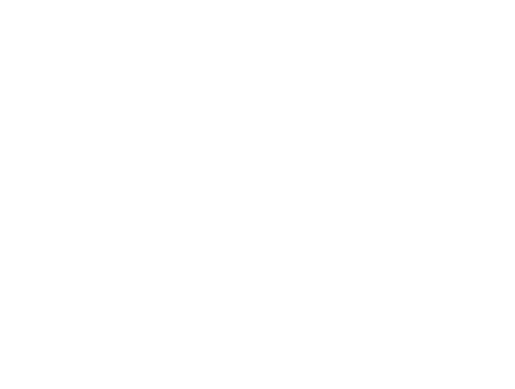

In [2]:
display(distributions.pivot(index='statistic', columns='distribution', values='cosine').round(6))
display(plt.imread(RESULTS / 'figures/archs4_pairwise_cosine.png'))
plt.axis('off'); plt.show()

## Ranked retrieval comparison

Only methods with a mathematically defined global ordering appear here.
`source_r1_known` is exact normalized `source_name_ch1` agreement—not an
inferred tissue, disease, treatment, or condition label.

In [3]:
cols = ['method','exact_r1','exact_r5','exact_r10','exact_r100','mrr','median_rank','same_gse_r1','source_r1_known','runtime_seconds']
display(comparison[cols].style.format({c:'{:.2%}' for c in ['exact_r1','exact_r5','exact_r10','exact_r100','same_gse_r1','source_r1_known']}).format({'mrr':'{:.4f}','runtime_seconds':'{:.2f}'}).hide(axis='index'))

method,exact_r1,exact_r5,exact_r10,exact_r100,mrr,median_rank,same_gse_r1,source_r1_known,runtime_seconds
Cosine,0.284698,0.695730,0.772242,0.918149,0.4764,2.000000,0.761566,0.722420,0.00
CSLS(k=5),0.298932,0.741993,0.814947,0.934164,0.5078,2.000000,0.724199,0.697509,5.39
CSLS(k=10),0.293594,0.740214,0.806050,0.941281,0.5039,2.000000,0.718861,0.699288,4.21
CSLS(k=50),0.197509,0.653025,0.749110,0.928826,0.3995,3.000000,0.619217,0.567616,4.61
LocalScaling(k=10),0.302491,0.752669,0.816726,0.943060,0.5119,2.000000,0.747331,0.717082,7.09
NICDM(k=10),0.304270,0.758007,0.825623,0.943060,0.5125,2.000000,0.741993,0.715302,2.83
Empirical-null cosine (global),0.284698,0.695730,0.772242,0.918149,0.4764,2.000000,0.761566,0.722420,0.17


array([[[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       ...,

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1.

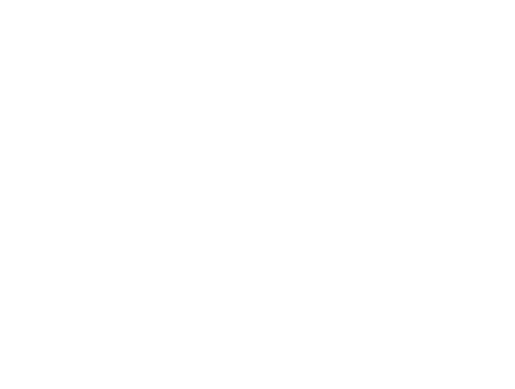

In [4]:
display(plt.imread(RESULTS / 'figures/ranked_method_comparison.png'))
plt.axis('off'); plt.show()

## Density stratification and set methods

The query strata are prespecified tertiles of mean cosine to ten nearest
references. Reciprocal-kNN and SNN are evaluated as returned sets rather than
being forced into global R@K/MRR.

In [5]:
primary = density[density.method.isin(['Cosine','CSLS(k=10)','LocalScaling(k=10)','NICDM(k=10)'])]
display(primary[['method','density_stratum','exact_r1','exact_r10','mrr','same_gse_r1']].style.format({c:'{:.2%}' for c in ['exact_r1','exact_r10','same_gse_r1']}).format({'mrr':'{:.4f}'}).hide(axis='index'))
display(set_metrics.style.format({'exact_set_recall':'{:.2%}','same_gse_set_recall':'{:.2%}','mean_returned':'{:.1f}','empty_fraction':'{:.2%}'}).hide(axis='index'))

method,density_stratum,exact_r1,exact_r10,mrr,same_gse_r1
CSLS(k=10),dense,0.245989,0.796791,0.4577,0.727273
CSLS(k=10),intermediate,0.395722,0.855615,0.6082,0.807487
CSLS(k=10),sparse,0.239362,0.765957,0.4461,0.622340
Cosine,dense,0.176471,0.743316,0.3875,0.802139
Cosine,intermediate,0.433155,0.898396,0.6358,0.882353
Cosine,sparse,0.244681,0.675532,0.4062,0.601064
LocalScaling(k=10),dense,0.224599,0.807487,0.4507,0.764706
LocalScaling(k=10),intermediate,0.433155,0.909091,0.6494,0.855615
LocalScaling(k=10),sparse,0.250000,0.734043,0.4360,0.622340
NICDM(k=10),dense,0.219251,0.828877,0.4468,0.754011


method,ranking_defined,k,exact_set_recall,same_gse_set_recall,mean_returned,empty_fraction
Mutual-kNN(k=1),False,1,39.15%,47.86%,0.6,38.79%
Mutual-kNN(k=5),False,5,65.48%,78.47%,3.9,3.74%
Mutual-kNN(k=10),False,10,75.80%,88.08%,8.4,0.71%
Mutual-kNN(k=100),False,100,91.99%,95.91%,99.9,0.00%
SNN-Jaccard(k=10),False,10,34.16%,51.25%,280.1,0.00%


array([[[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       ...,

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1.

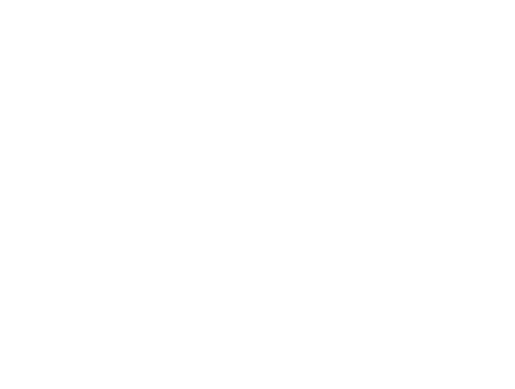

In [6]:
display(plt.imread(RESULTS / 'figures/density_stratified_retrieval.png'))
plt.axis('off'); plt.show()

## Hubness, diagnostics, and interpretation

Cosine has strong hub concentration. Local corrections reduce maximum N_k and
top-hub assignment share, but their modest exact-GSM gains trade against
same-GSE/source Top-1 agreement. Objective per-query gains, losses, unchanged
cases, and dense failures are saved in `rank_change_diagnostics.csv`.

The evidence supports offering NICDM or local scaling as a retrieval-time
reranker alongside cosine. It does not yet justify representation learning:
Stages 2–4 were not implemented or run.

method,k,references_selected,max_nk,skewness,gini,top_10_hubs_assignment_fraction
Cosine,1,396,16,122.56,0.9994,14.06%
Cosine,100,13179,74,22.92,0.9893,1.24%
CSLS(k=5),1,459,8,70.23,0.9993,9.07%
CSLS(k=5),100,17511,58,20.30,0.9841,0.93%
CSLS(k=10),1,441,8,67.81,0.9993,9.25%
CSLS(k=10),100,17267,54,19.69,0.9841,0.90%
CSLS(k=50),1,385,9,80.66,0.9994,11.74%
CSLS(k=50),100,16438,48,17.68,0.9850,0.78%
LocalScaling(k=10),1,426,9,75.01,0.9993,9.96%
LocalScaling(k=10),100,16294,44,16.57,0.9847,0.73%


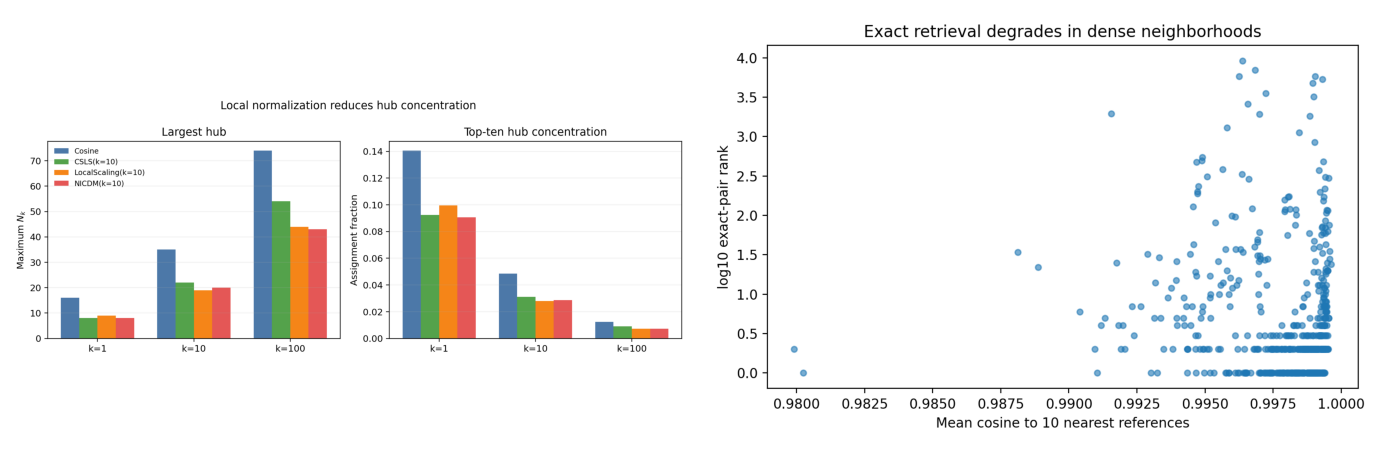

In [7]:
display(hubness[hubness.k.isin([1,100])][['method','k','references_selected','max_nk','skewness','gini','top_10_hubs_assignment_fraction']].style.format({'skewness':'{:.2f}','gini':'{:.4f}','top_10_hubs_assignment_fraction':'{:.2%}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ['hubness_comparison.png', 'density_vs_cosine_rank.png']):
    ax.imshow(plt.imread(RESULTS / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Calibration and rank-change diagnostics

The global empirical null is monotone and cannot change cosine ranking. Its
P-values nevertheless differ across density strata. Rank-change distributions
show the full balance of gains and losses rather than selected anecdotes; the
objective representative cases remain available in the saved diagnostics table.

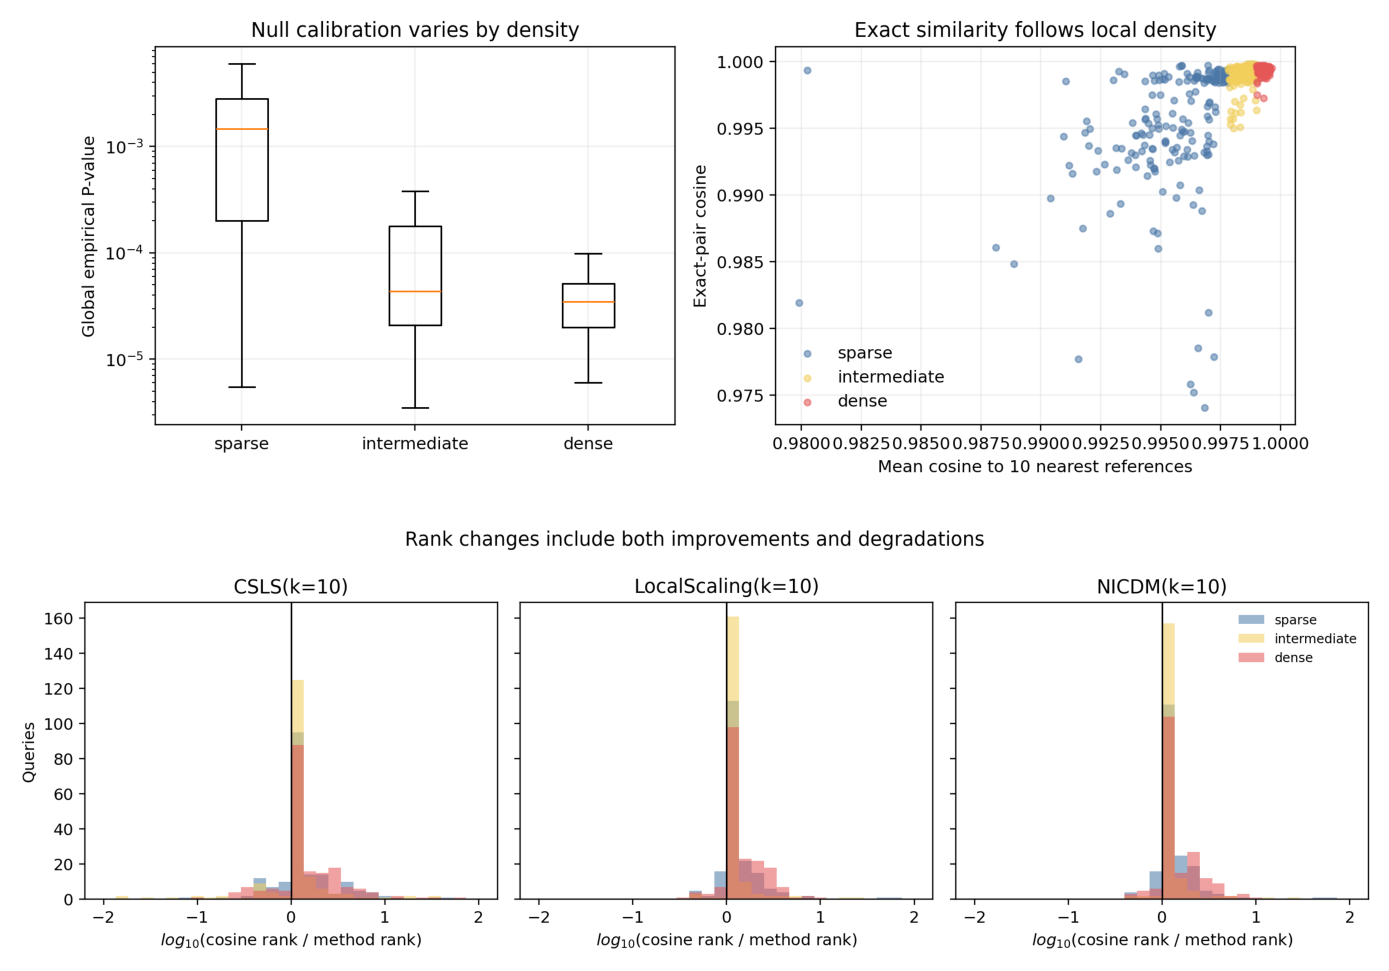

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
for ax, name in zip(axes, ['empirical_null_density_calibration.png', 'rank_change_distributions.png']):
    ax.imshow(plt.imread(RESULTS / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

# Stage 1A–1H: composition-controlled biological validation

**Primary composition result.** The benchmark is not balanced: GSE234297 and
its `peripheral blood` source contribute 144/562 queries (25.6%), and the five
largest studies contribute 51.1%. Of 187 dense queries, 122 (65.2%) come from
that single study/source. Cell type, cell line, disease, treatment, and
primary-versus-cultured status are not available as curated corpus-wide fields
and were not inferred from free text.

dimension,classes,largest,largest_fraction,top5_fraction,effective_n_shannon,effective_n_inverse_simpson
study,40,GSE234297,25.6%,51.1%,19.2,10.6
normalized_source,92,peripheral blood,25.6%,44.8%,34.3,12.2


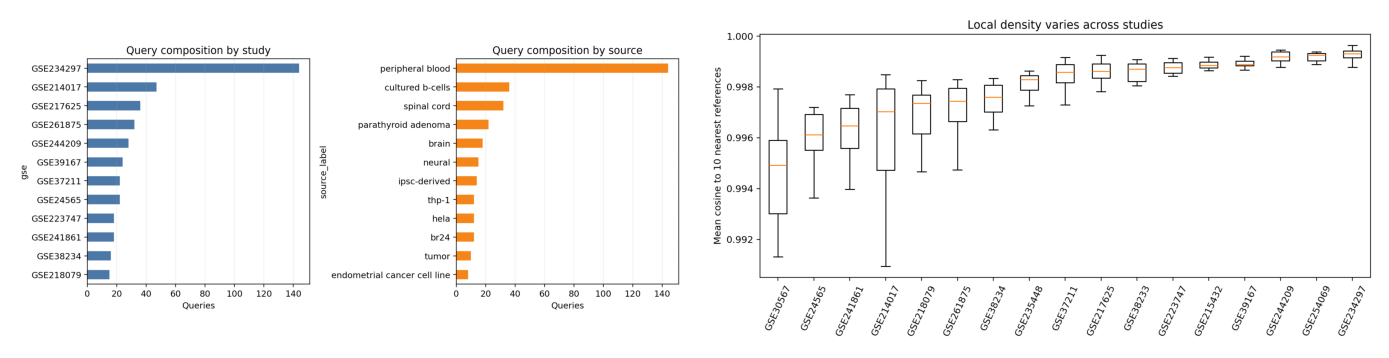

In [9]:
display(composition.style.format({'largest_fraction':'{:.1%}','top5_fraction':'{:.1%}','effective_n_shannon':'{:.1f}','effective_n_inverse_simpson':'{:.1f}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ['query_composition.png', 'density_by_study.png']):
    ax.imshow(plt.imread(BIO / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

array([[[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       ...,

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1.

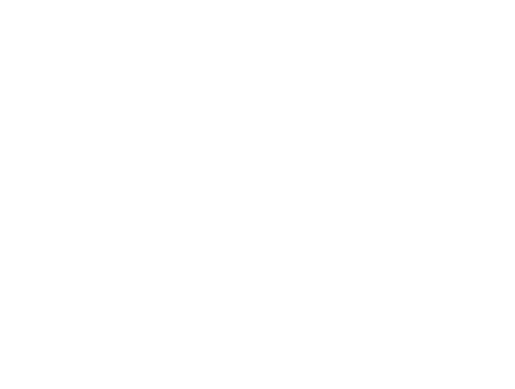

In [10]:
display(plt.imread(BIO / 'figures/density_by_source.png'))
plt.axis('off'); plt.show()

## Does density remain associated after composition controls?

The dense-minus-sparse failure difference is +6.8 percentage points overall
but −1.7 points after excluding GSE234297/peripheral blood. Conditional models
show no precise independent density association. The earlier dense-stratum
failure pattern is therefore largely composition-driven in this cohort.

model,samples,strata,odds_ratio_per_density_sd,ci_low,ci_high,p_value
unadjusted logistic,562,nan,0.86,0.70,1.06,0.149
study fixed effects,452,19.000000,0.98,0.69,1.40,0.930
source fixed effects,421,31.000000,0.89,0.63,1.27,0.523
dense vs sparse unadjusted,375,nan,1.51,0.92,2.50,0.107
"dense vs sparse, study fixed effects",281,15.000000,3.24,0.49,21.63,0.224
"dense vs sparse, source fixed effects",244,18.000000,0.71,0.12,4.18,0.709


array([[[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       ...,

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1.

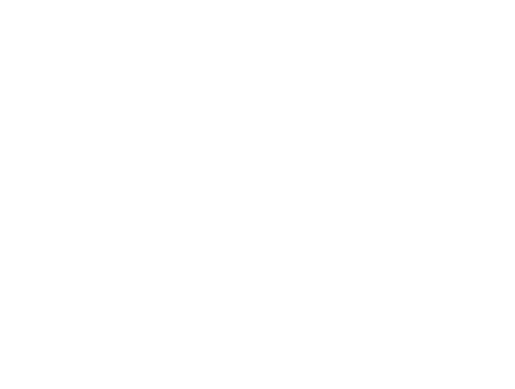

In [11]:
display(density_models.style.format({'odds_ratio_per_density_sd':'{:.2f}','ci_low':'{:.2f}','ci_high':'{:.2f}','p_value':'{:.3f}'}).hide(axis='index'))
display(plt.imread(BIO / 'figures/density_failure_effects.png')); plt.axis('off'); plt.show()

## Biological-label quality and retrieval

Exact normalized `source_name_ch1` is structured and complete but heterogeneous
across submitters. The conservative inherited tissue mapping covers only 162
queries—144 blood and 18 brain—so tissue results are a limited sensitivity
analysis. The exact paired GSM is excluded below; cross-study results also
exclude every reference from the query GSE.

label,labeled_queries,eligible_queries,labeled_references,eligible_references,eligible_classes_corpus,classes_in_eligible_queries,ambiguous_references,largest_query_class_fraction,query_missing_fraction,reference_missing_fraction
source_label,562,286,510709,228556,731,23,0,50.3%,0.0%,0.0%
tissue_label,162,162,73162,73162,16,2,0,88.9%,71.2%,85.7%


method,exact_r1,exact_r10,biological_p1,biological_p10,cross_study_biological_p1,cross_study_biological_p10,hubness_max_n100,hubness_gini_n100
Cosine,0.284698,0.772242,0.664336,0.495105,0.031469,0.018531,74,0.989
CSLS(k=10),0.293594,0.806050,0.538462,0.372378,0.027972,0.018881,54,0.984
LocalScaling(k=10),0.302491,0.816726,0.573427,0.385315,0.020979,0.016783,44,0.985
NICDM(k=10),0.304270,0.825623,0.562937,0.368182,0.020979,0.017133,43,0.984


method,exact_r1,exact_r10,biological_p1,biological_p10,cross_study_biological_p1,cross_study_biological_p10,hubness_max_n100,hubness_gini_n100
Cosine,0.284698,0.772242,0.820988,0.688272,0.345679,0.308025,74,0.989
CSLS(k=10),0.293594,0.806050,0.753086,0.628395,0.425926,0.390123,54,0.984
LocalScaling(k=10),0.302491,0.816726,0.746914,0.621605,0.407407,0.382716,44,0.985
NICDM(k=10),0.304270,0.825623,0.765432,0.603704,0.413580,0.371605,43,0.984


array([[[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       ...,

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1.

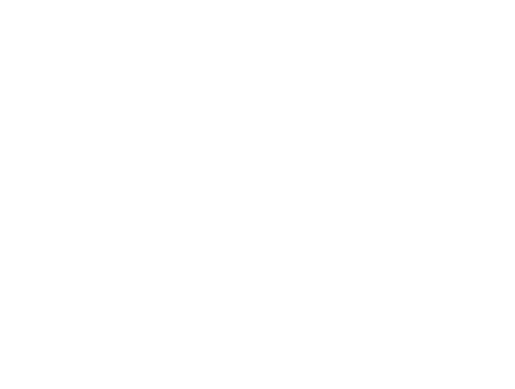

In [12]:
display(label_qc.style.format({'largest_query_class_fraction':'{:.1%}','query_missing_fraction':'{:.1%}','reference_missing_fraction':'{:.1%}'}).hide(axis='index'))
display(source_comparison.style.format({c:'{:.1%}' for c in ['exact_r1','exact_r10','biological_p1','biological_p10','cross_study_biological_p1','cross_study_biological_p10']}).format({'hubness_gini_n100':'{:.3f}'}).hide(axis='index'))
display(tissue_comparison.style.format({c:'{:.1%}' for c in ['exact_r1','exact_r10','biological_p1','biological_p10','cross_study_biological_p1','cross_study_biological_p10']}).format({'hubness_gini_n100':'{:.3f}'}).hide(axis='index'))
display(plt.imread(BIO / 'figures/biological_retrieval_comparison.png')); plt.axis('off'); plt.show()

## Density-stratified biology, set retrieval, and diversity

Cosine preserves the strongest within-corpus source neighborhoods. Local
normalization improves exact identity and reduces study redundancy but lowers
source precision. In the limited blood/brain task, corrections improve
cross-study tissue retrieval. SNN maximum-score sets are too broad to serve as
selective retrieval results.

label,method,scope,queries,mean_returned,nonempty_fraction,mean_set_precision,any_same_label
source_label,Mutual-kNN(k=10),cross_study,286,4.5,80.4%,2.7%,4.5%
source_label,Mutual-kNN(k=10),full_no_exact,286,7.5,98.3%,41.8%,71.0%
source_label,SNN-Jaccard(k=10),cross_study,286,150.0,93.7%,2.4%,21.3%
source_label,SNN-Jaccard(k=10),full_no_exact,286,150.9,98.3%,11.1%,47.9%
tissue_label,Mutual-kNN(k=10),cross_study,162,4.0,89.5%,37.2%,62.3%
tissue_label,Mutual-kNN(k=10),full_no_exact,162,6.7,97.5%,64.0%,92.6%
tissue_label,SNN-Jaccard(k=10),cross_study,162,80.8,91.4%,41.7%,59.9%
tissue_label,SNN-Jaccard(k=10),full_no_exact,162,81.2,98.1%,49.3%,74.1%


method,scope,unique_gse_top10,unique_source_top10,largest_gse_fraction_top10,largest_source_fraction_top10
CSLS(k=10),cross_study,5.30,5.39,40.9%,39.8%
CSLS(k=10),full_no_exact,4.42,4.87,52.8%,47.6%
Cosine,cross_study,5.20,5.45,41.4%,39.0%
Cosine,full_no_exact,3.93,4.60,59.5%,51.4%
LocalScaling(k=10),cross_study,5.31,5.43,40.3%,40.0%
LocalScaling(k=10),full_no_exact,4.33,4.85,53.6%,48.2%
NICDM(k=10),cross_study,5.32,5.45,40.6%,39.7%
NICDM(k=10),full_no_exact,4.44,4.94,52.0%,46.8%


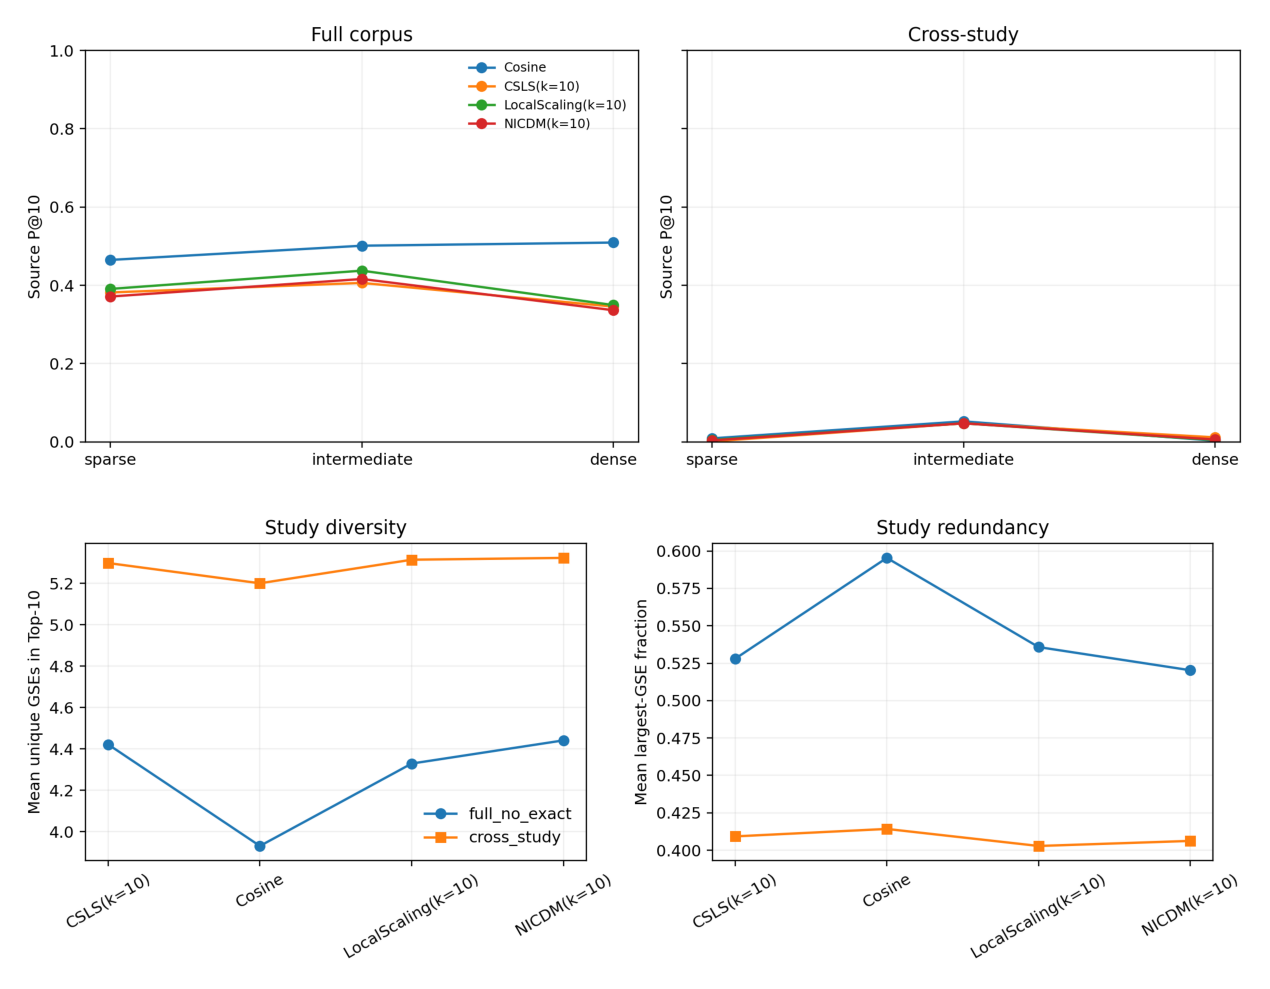

In [13]:
display(set_biology.style.format({'mean_returned':'{:.1f}','nonempty_fraction':'{:.1%}','mean_set_precision':'{:.1%}','any_same_label':'{:.1%}'}).hide(axis='index'))
display(diversity.style.format({'unique_gse_top10':'{:.2f}','unique_source_top10':'{:.2f}','largest_gse_fraction_top10':'{:.1%}','largest_source_fraction_top10':'{:.1%}'}).hide(axis='index'))
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
for ax, name in zip(axes, ['density_stratified_biological_retrieval.png', 'retrieval_diversity.png']):
    ax.imshow(plt.imread(BIO / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Objective-specific recommendation

- **Technical identity:** NICDM, with local scaling close behind.
- **Within-corpus biological source:** cosine.
- **Cross-study biology:** not resolved by available metadata; corrections win
  the limited blood/brain tissue sensitivity analysis, but exact source labels
  do not transfer across submitters.

The density effect is largely driven by one peripheral-blood study, and metadata
are insufficient for a trustworthy cell-state objective. Representation
correction is not warranted from these results. Stages 2–4 remain unimplemented.

# recount3 discovery audit and study balancing

The upstream run started from every predefined human, unseen, mapped-single
Bridge sample in both exposure cohorts (84,896 candidates). It traversed the
full contemporaneous human recount3 SRA project catalog, but only 8,199/8,803
project metadata files were readable; 604 failures prevent a strict claim of
exhaustiveness. The preserved tables—not the later-edited upstream config—show
that 574 pairs were processed: 562 unseen-study and 12 unseen-sample/seen-study.

The audit below is metadata-only. It reused saved ranks and the existing
recount3 metadata restart cache; it downloaded no expression and generated no
embeddings.

In [14]:
display(funnel)
display(cohort_inventory)
display(expansion)

,step,samples,studies,removed_from_prior,reason
0,Bridge human samples,510709,26262,NaN,Frozen master manifest
1,Predefined unseen split,110709,5678,400000.0,split == unseen
2,Single-GSE eligible candidates,84896,4375,25813.0,mapping_status == mapped_single; both exposure...
3,Frozen discovery candidates,84896,4375,0.0,All eligible rows retained; no subsampling
4,Any recount3 metadata match,575,43,84321.0,"Catalog-wide scan: 8,199/8,803 project metadat..."
5,Unambiguous project with run(s),574,42,1.0,One multiple-project GSM excluded; no matched_...
6,Expression downloaded / vocabulary compatible,574,42,0.0,"All 574 selected pairs processed on 15,165 can..."
7,Published strict unseen-study benchmark,562,40,12.0,Notebook/report filter; 12 unseen-sample/seen-...


,study_exposure,mapping_status,bridge_samples,gse_labels,cached_metadata_hits,unambiguous_cached_candidates,existing_upstream_pairs,additional_candidates
0,seen_study,mapped_multiple,2984,167,1,1,0,1
1,seen_study,mapped_single,2308,120,13,12,12,0
2,unseen_study,mapped_multiple,22829,1136,257,257,0,257
3,unseen_study,mapped_single,82588,4255,562,562,562,0


,cohort,bridge_samples,existing_published_pairs,existing_upstream_pairs,additional_cached_candidates,additional_candidate_gse_labels,largest_candidate_gse_fraction,mapped_single_additional,mapped_multiple_additional
0,seen_study,5292,0,12,1,1,1.000000,0,1
1,unseen_study,105417,562,562,257,23,0.428016,0,257


## Balanced exact-pair retrieval

Study-macro evaluation gives every one of the 40 studies equal weight. Local
scaling and NICDM retain modest R@5/R@10 advantages, while CSLS no longer
improves on cosine. Cap-5 and cap-10 subsets are deterministic and were chosen
without using density or retrieval outcomes.

method,studies,macro_r_at_1,macro_r_at_5,macro_r_at_10,macro_r_at_100,macro_mrr
CSLS(k=10),40,0.225035,0.605861,0.660072,0.838273,0.4066
Cosine,40,0.329651,0.659714,0.759189,0.913273,0.4886
LocalScaling(k=10),40,0.342651,0.720826,0.786634,0.932197,0.5155
NICDM(k=10),40,0.346812,0.716600,0.789611,0.928204,0.5163


cap,method,studies,queries,r_at_1,r_at_5,r_at_10,r_at_100,mrr
5,Cosine,40,154,0.311688,0.662338,0.720779,0.896104,0.4730
5,CSLS(k=10),40,154,0.272727,0.649351,0.694805,0.883117,0.4498
5,LocalScaling(k=10),40,154,0.324675,0.720779,0.766234,0.909091,0.5068
5,NICDM(k=10),40,154,0.318182,0.714286,0.766234,0.902597,0.4984
10,Cosine,40,248,0.318548,0.697581,0.766129,0.907258,0.4932
10,CSLS(k=10),40,248,0.294355,0.701613,0.750000,0.915323,0.4864
10,LocalScaling(k=10),40,248,0.330645,0.741935,0.794355,0.927419,0.5209
10,NICDM(k=10),40,248,0.322581,0.737903,0.798387,0.923387,0.5142


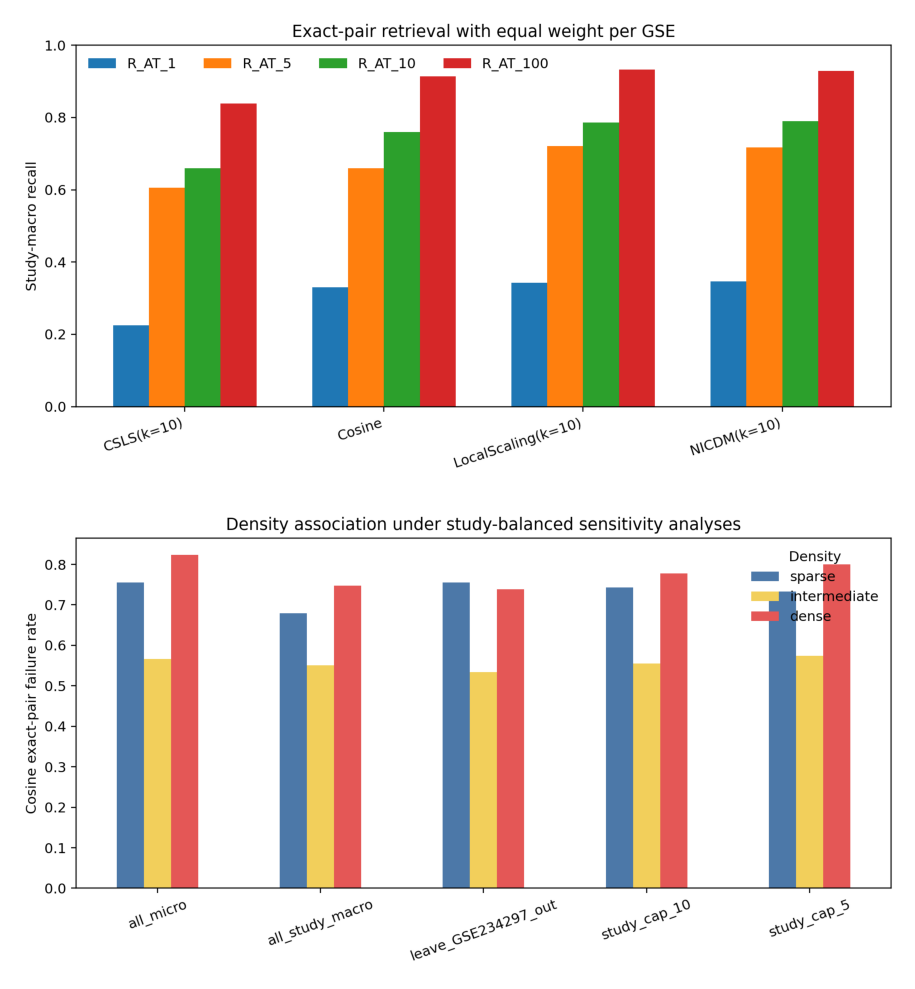

In [15]:
macro_cols = ['method','studies','macro_r_at_1','macro_r_at_5','macro_r_at_10','macro_r_at_100','macro_mrr']
display(macro[macro_cols].style.format({c:'{:.1%}' for c in macro_cols if c.startswith('macro_r')}).format({'macro_mrr':'{:.4f}'}).hide(axis='index'))
display(capped.style.format({c:'{:.1%}' for c in ['r_at_1','r_at_5','r_at_10','r_at_100']}).format({'mrr':'{:.4f}'}).hide(axis='index'))
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
for ax, name in zip(axes, ['study_macro_retrieval.png', 'balanced_density_sensitivity.png']):
    ax.imshow(plt.imread(AUDIT / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Expansion decision

Within the original mapped-single eligibility criteria, the readable recount3
snapshot contains no unprocessed candidates. A broader cached-metadata
intersection identifies 257 unseen-study and one seen-study candidate, but all
258 have ambiguous multi-GSE manifest mappings and were deliberately outside
the original protocol. The 257 unseen-study candidates add neural/brain-heavy
contexts and 43 component GSEs not in the 562, but one composite GSE label still
accounts for 42.8%.

Keep the strict 562 and report study-macro metrics alongside micro metrics.
Consider the 257 only as a separately named, manually adjudicated expansion;
do not merge them into the existing benchmark. No expression processing,
embedding generation, or representation learning was performed.

# Absolute similarity versus retrieval uniqueness

Bridge cosine and retrieval rank answer different questions. Exact-pair cosine
measures absolute agreement between independent ARCHS4 and recount3 processing.
Rank measures whether other samples in the 510,709-reference corpus are even
closer. The analysis below reuses the saved score cache and random-pair sample;
it performs no embedding inference or new retrieval search.

samples,studies,sample_level_mean_cosine,sample_level_median_cosine,study_macro_mean_cosine,study_macro_median_cosine,median_across_study_means,median_across_study_medians,sd_across_study_means,minimum_study_mean,maximum_study_mean
562,40,0.997806,0.999218,0.996569,0.996740,0.998803,0.998942,0.004667,0.977107,0.999689


rank_group,n,mean,median,sd,q1,q3,minimum,maximum
Rank 1,160,0.999237,0.999385,0.000481,0.998961,0.999564,0.996436,0.999822
Rank 2–5,231,0.998683,0.999317,0.001863,0.998697,0.999525,0.981911,0.999822
Rank 6–10,43,0.997244,0.998624,0.002742,0.994999,0.999381,0.989748,0.999444
Rank 11–100,82,0.995938,0.996405,0.003545,0.993314,0.999110,0.984819,0.999493
"Rank 101–1,000",32,0.994699,0.995907,0.004281,0.991411,0.998770,0.985970,0.999223
"Rank >1,000",14,0.986743,0.985951,0.010182,0.977758,0.997191,0.974058,0.997903
All 562,562,0.997806,0.999218,0.003510,0.998496,0.999460,0.974058,0.999822


array([[[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       ...,

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1.

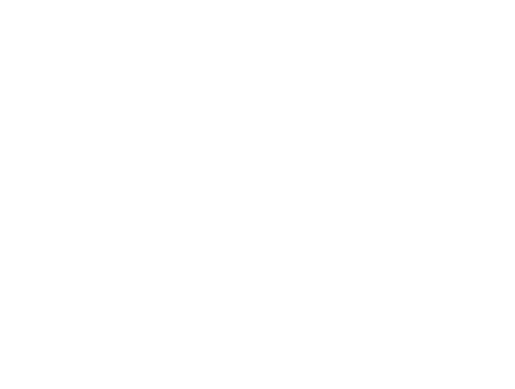

In [16]:
display(cosine_micro_macro.style.format({c:'{:.6f}' for c in cosine_micro_macro.columns if 'cosine' in c or 'study_mean' in c}).hide(axis='index'))
display(cosine_by_rank[['rank_group','n','mean','median','sd','q1','q3','minimum','maximum']].style.format({c:'{:.6f}' for c in ['mean','median','sd','q1','q3','minimum','maximum']}).hide(axis='index'))
display(plt.imread(ABS / 'figures/exact_cosine_vs_rank.png')); plt.axis('off'); plt.show()

## Expanded micro and study-macro retrieval

Micro metrics give every one of 562 queries equal weight. Study-macro metrics
first score each GSE and then give every one of 40 studies equal weight.
R@1,000 represents only 0.1958% of the reference corpus and is included to
describe the tail rather than as a primary success criterion.

In [17]:
micro_cols=['method','r_at_1','r_at_5','r_at_10','r_at_100','r_at_1000','mrr','median_rank','mean_rank','median_percentile_rank']
display(expanded_micro[micro_cols].style.format({c:'{:.1%}' for c in ['r_at_1','r_at_5','r_at_10','r_at_100','r_at_1000']}).format({'mrr':'{:.4f}','mean_rank':'{:.2f}','median_percentile_rank':'{:.6f}'}).hide(axis='index'))
macro_cols=['method','macro_r_at_1','macro_r_at_5','macro_r_at_10','macro_r_at_100','macro_r_at_1000','macro_mrr']
display(expanded_macro[macro_cols].style.format({c:'{:.1%}' for c in macro_cols if c.startswith('macro_r')}).format({'macro_mrr':'{:.4f}'}).hide(axis='index'))

method,r_at_1,r_at_5,r_at_10,r_at_100,r_at_1000,mrr,median_rank,mean_rank,median_percentile_rank
Cosine,0.284698,0.695730,0.772242,0.918149,0.975089,0.4764,2.000000,119.46,0.999998
CSLS(k=10),0.293594,0.740214,0.806050,0.941281,0.980427,0.5039,2.000000,69.78,0.999998
LocalScaling(k=10),0.302491,0.752669,0.816726,0.943060,0.985765,0.5119,2.000000,66.02,0.999998
NICDM(k=10),0.304270,0.758007,0.825623,0.943060,0.985765,0.5125,2.000000,59.49,0.999998


method,macro_r_at_1,macro_r_at_5,macro_r_at_10,macro_r_at_100,macro_r_at_1000,macro_mrr
Cosine,0.329651,0.659714,0.759189,0.913273,0.969792,0.4886
CSLS(k=10),0.225035,0.605861,0.660072,0.838273,0.949479,0.4066
LocalScaling(k=10),0.342651,0.720826,0.786634,0.932197,0.974653,0.5155
NICDM(k=10),0.346812,0.716600,0.789611,0.928204,0.974653,0.5163


## Random-pair placement and near-tied neighborhoods

The exact-pair median lies at the empirical 99.9936th percentile of the saved
two-million random ARCHS4-pair distribution. Yet poor-rank queries can have
thousands of references close to their exact-pair cosine. Counts below use
`reference cosine >= exact cosine - delta`, including closer references and
the exact counterpart.

distribution,n,mean,median,sd,q1,q3,minimum,maximum,p1,p5,p95,p99
Random ARCHS4 pairs,2000000,0.878748,0.912954,0.118144,0.862537,0.941537,-0.443058,0.999929,0.354765,0.673433,0.967828,0.984401
Exact ARCHS4-recount3 pairs,562,0.997806,0.999218,0.003510,0.998496,0.999460,0.974058,0.999822,0.980139,0.991977,0.999658,0.999731


exact_statistic,cosine,random_pairs_at_or_below,random_pair_empirical_percentile,random_pairs_exceeding_fraction
exact_minimum,0.974058,1942820,97.1410%,2.8590%
exact_q1,0.998496,1999451,99.9725%,0.0275%
exact_median,0.999218,1999872,99.9936%,0.0064%


rank_threshold,cosine_threshold,queries,fraction_all_queries,fraction_among_poor_rank
100,0.990000,33,5.87%,71.74%
100,0.995000,25,4.45%,54.35%
100,0.999000,4,0.71%,8.70%
1000,0.990000,7,1.25%,50.00%
1000,0.995000,6,1.07%,42.86%
1000,0.999000,0,0.00%,0.00%


criterion,selection_order,gsm,gse,source,exact_rank,exact_pair_cosine,top1_cosine,top1_minus_exact_cosine,references_at_least_exact_minus_0_001,references_at_least_exact_minus_0_005
exact_rank_gt_100,1,GSM7461825,GSE234297,peripheral blood,107,0.999223,0.999513,0.000290,2927,13615
exact_rank_gt_100,2,GSM7461702,GSE234297,peripheral blood,115,0.999102,0.999591,0.000489,659,4429
exact_rank_gt_100,3,GSM7461804,GSE234297,peripheral blood,116,0.999076,0.999541,0.000464,1591,11239
exact_rank_gt_100,4,GSM7461761,GSE234297,peripheral blood,153,0.999034,0.999539,0.000504,3247,13274
exact_rank_gt_100,5,GSM7461798,GSE234297,peripheral blood,296,0.998961,0.999686,0.000726,1786,9946
exact_rank_gt_1000,1,GSM7461712,GSE234297,peripheral blood,1825,0.997903,0.999059,0.001156,6053,14974
exact_rank_gt_1000,2,GSM7461716,GSE234297,peripheral blood,5809,0.997487,0.999063,0.001576,9599,17752
exact_rank_gt_1000,3,GSM7461768,GSE234297,peripheral blood,5322,0.997250,0.999513,0.002263,8035,15628
exact_rank_gt_1000,4,GSM7461726,GSE234297,peripheral blood,1116,0.997228,0.998603,0.001375,3654,12561
exact_rank_gt_1000,5,GSM7461824,GSE234297,peripheral blood,4766,0.997082,0.999090,0.002008,8378,16563


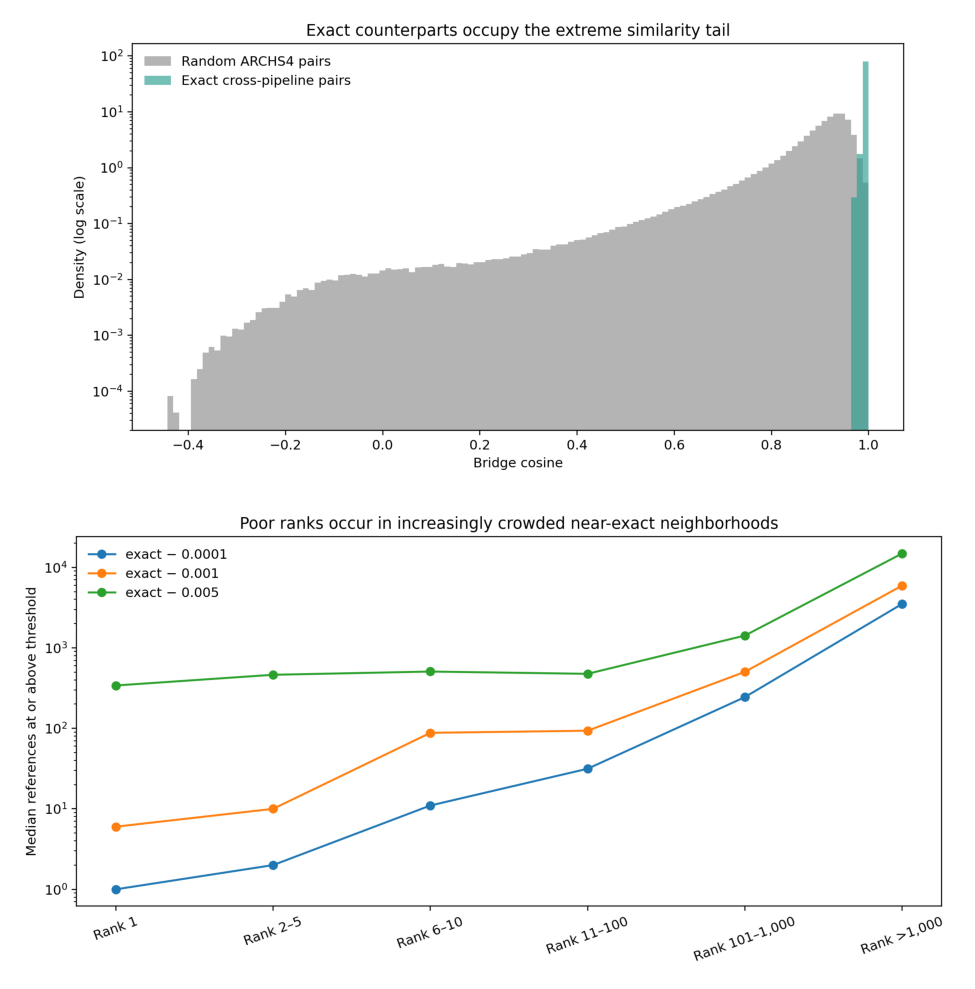

In [18]:
display(random_exact.style.format({c:'{:.6f}' for c in ['mean','median','sd','q1','q3','minimum','maximum','p1','p5','p95','p99']}).hide(axis='index'))
display(random_percentiles.style.format({'cosine':'{:.6f}','random_pair_empirical_percentile':'{:.4%}','random_pairs_exceeding_fraction':'{:.4%}'}).hide(axis='index'))
display(poor_rank_frequency.style.format({'fraction_all_queries':'{:.2%}','fraction_among_poor_rank':'{:.2%}'}).hide(axis='index'))
display(poor_rank_examples.style.format({'exact_pair_cosine':'{:.6f}','top1_cosine':'{:.6f}','top1_minus_exact_cosine':'{:.6f}'}).hide(axis='index'))
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
for ax, name in zip(axes, ['random_vs_exact_cosine.png','near_exact_neighbors_by_rank.png']):
    ax.imshow(plt.imread(ABS / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Native ranking scores

Each row is grouped by that method's own exact-counterpart rank. Only the
cosine method's native score is Bridge cosine. CSLS, local-scaling, and NICDM
values are transformed ranking criteria, whose numerical scales should not be
compared with cosine or with one another.

In [19]:
display(native_scores[['method','rank_group','native_score_n','native_score_mean','native_score_median','native_score_q1','native_score_q3','bridge_cosine_median']].style.format({c:'{:.6f}' for c in ['native_score_mean','native_score_median','native_score_q1','native_score_q3','bridge_cosine_median']}).hide(axis='index'))

method,rank_group,native_score_n,native_score_mean,native_score_median,native_score_q1,native_score_q3,bridge_cosine_median
Cosine,Rank 1,160,0.999237,0.999385,0.998961,0.999564,0.999385
Cosine,Rank 2–5,231,0.998683,0.999317,0.998697,0.999525,0.999317
Cosine,Rank 6–10,43,0.997244,0.998624,0.994999,0.999381,0.998624
Cosine,Rank 11–100,82,0.995938,0.996405,0.993314,0.999110,0.996405
Cosine,"Rank 101–1,000",32,0.994699,0.995907,0.991411,0.998770,0.995907
Cosine,"Rank >1,000",14,0.986743,0.985951,0.977758,0.997191,0.985951
CSLS(k=10),Rank 1,165,0.004153,0.001660,0.000939,0.003349,0.999380
CSLS(k=10),Rank 2–5,251,0.003924,0.001637,0.000519,0.003641,0.999309
CSLS(k=10),Rank 6–10,37,0.002357,-0.000031,-0.000329,0.001165,0.998488
CSLS(k=10),Rank 11–100,76,0.003327,0.000688,-0.000212,0.007616,0.998444


## Interpretation

Mean/median exact-pair cosine is 0.997806/0.999218, and equal-study weighting
still gives a macro mean of 0.996569. Cross-pipeline representation agreement
is therefore broadly strong. Forty-six queries rank below 100 despite this;
33 still exceed cosine 0.99 and four exceed 0.999. For rank >1,000 queries, the
median neighborhood contains 5,944.5 references above exact−0.001 and 14,889
above exact−0.005. These are primarily retrieval-uniqueness failures in crowded
regions, not simple representation-agreement failures. Native local-scaling,
NICDM, and CSLS scores remain ranking criteria—not cosine similarities.

# ARCHS4 anisotropy and common components

The mean and PCA basis below were fit once on all 510,709 ARCHS4 references;
the same transform was then applied unchanged to recount3 queries. The squared
norm of the mean unit direction is 0.878774—essentially the observed random-pair
mean cosine 0.878748. Most samples therefore share a large global direction.
Mean-centering moves the random median from 0.912954 to −0.002471.

references,embedding_dim,global_raw_mean_norm,mean_raw_sample_norm,median_raw_sample_norm,mean_norm_to_mean_sample_norm_ratio,unit_directional_mean_norm,unit_directional_mean_norm_squared,mean_sample_cosine_to_raw_mean_direction,median_sample_cosine_to_raw_mean_direction,mean_sample_cosine_to_unit_mean_direction,median_sample_cosine_to_unit_mean_direction,sample_to_unit_mean_cosine_sd,pc1_mean_direction_absolute_cosine,participation_ratio,effective_dimension_fraction
510709,512,9.990911,10.630730,10.191850,0.939814,0.937430,0.878774,0.936675,0.961514,0.937429,0.959450,0.079727,0.723283,2.907422,0.005679


pc1,pc2,pc5_cumulative,pc10_cumulative,pc20_cumulative,pc50_cumulative,participation_ratio,pc1_mean_direction_absolute_cosine
0.576646,0.077823,0.749605,0.829621,0.911234,0.981979,2.907422,0.723283


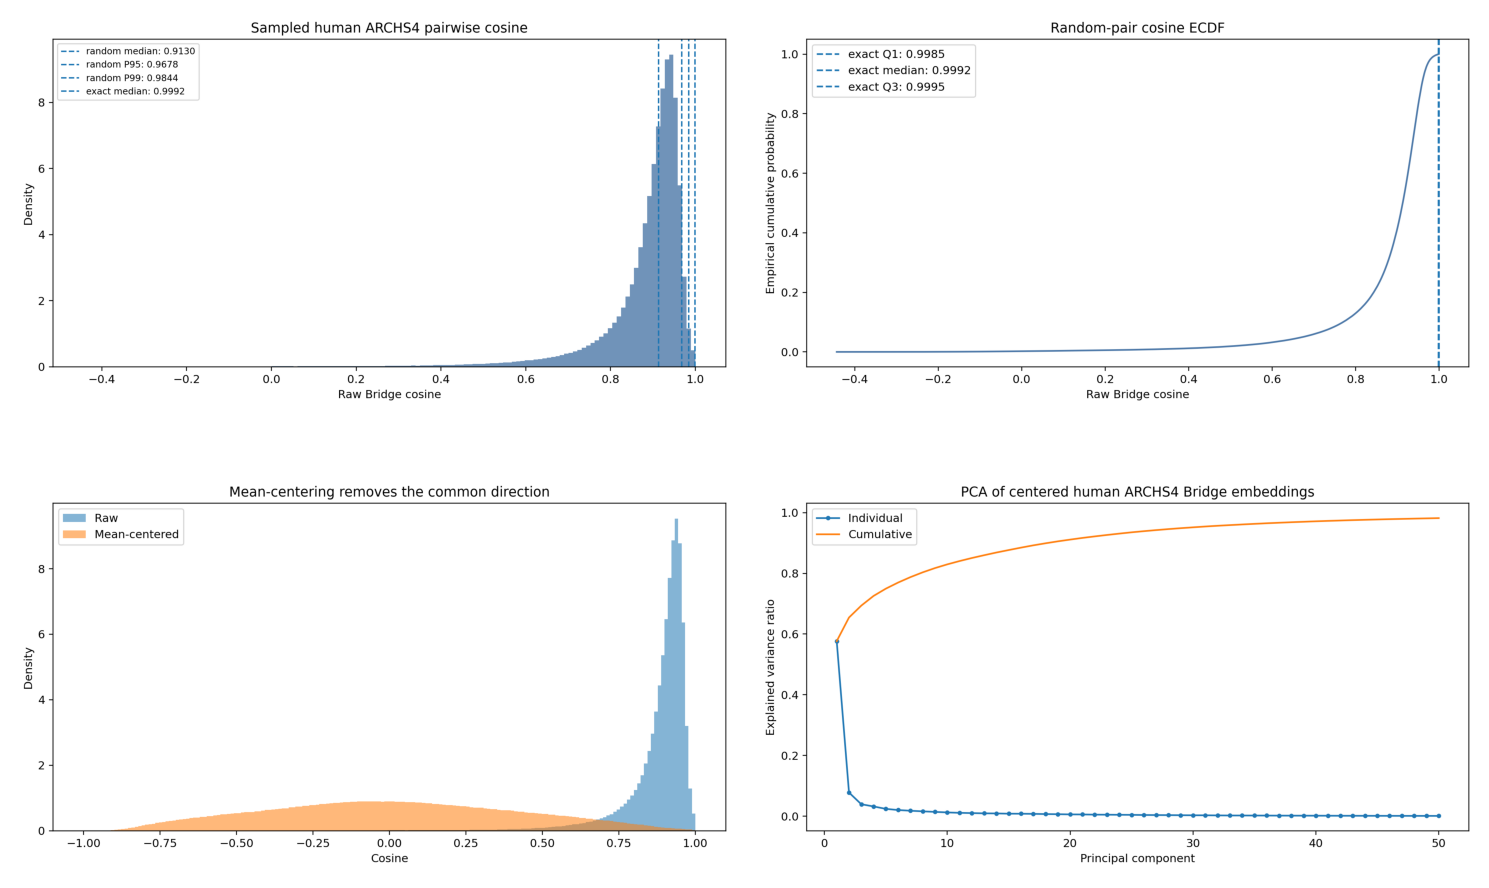

In [20]:
display(anisotropy.style.format({c:'{:.6f}' for c in anisotropy.columns if c not in ['references','embedding_dim']}).hide(axis='index'))
display(pca_summary.style.format('{:.6f}').hide(axis='index'))
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, name in zip(axes.ravel(), ['raw_random_cosine_histogram.png','raw_random_cosine_ecdf.png','raw_vs_centered_cosine.png','pca_explained_variance.png']):
    ax.imshow(plt.imread(ANISO / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Geometry, separation, and exact retrieval

Centered PC1 explains 57.7% of variance and the covariance participation ratio
is only 2.91 effective dimensions. Centering alone degrades retrieval, but
removing ten centered PCs improves exact R@1 to 37.2%, R@10 to 85.4%, and
study-macro R@10 to 84.5%, exceeding NICDM/local scaling in this paired task.
PC count was evaluated diagnostically here and must be frozen before external
biological evaluation.

representation,distribution,n,mean,median,sd,p5,p95,p99
Raw,random_ARCHS4_pairs,2000000,0.878748,0.912954,0.118144,0.673433,0.967828,0.984401
Mean-centered,random_ARCHS4_pairs,2000000,0.006452,-0.002471,0.406919,-0.655725,0.692437,0.863638
Centered + remove PC1,random_ARCHS4_pairs,2000000,0.004760,-0.025625,0.246451,-0.338807,0.466083,0.788729
Centered + remove PCs 1–2,random_ARCHS4_pairs,2000000,0.002777,-0.021669,0.208268,-0.277116,0.375084,0.761399
Centered + remove PCs 1–5,random_ARCHS4_pairs,2000000,0.001718,-0.019016,0.187970,-0.253360,0.322849,0.685160
Centered + remove PCs 1–10,random_ARCHS4_pairs,2000000,0.001168,-0.011327,0.180508,-0.258152,0.289961,0.644133
Raw,exact_ARCHS4_recount3_pairs,562,0.997806,0.999218,0.003510,0.991977,0.999658,0.999731
Mean-centered,exact_ARCHS4_recount3_pairs,562,0.985264,0.990891,0.024900,0.948229,0.997122,0.997695
Centered + remove PC1,exact_ARCHS4_recount3_pairs,562,0.966366,0.985575,0.059921,0.835426,0.992340,0.994938
Centered + remove PCs 1–2,exact_ARCHS4_recount3_pairs,562,0.963784,0.984695,0.061349,0.831924,0.992881,0.994398


representation,mean_difference,median_difference,cohens_d_pooled,exact_median_random_percentile,exact_q1_random_percentile,similarity_auroc
Raw,0.119058,0.086264,1.007876,0.999936,0.999726,0.999096
Mean-centered,0.978813,0.993363,2.405761,0.999862,0.999730,0.999411
Centered + remove PC1,0.961606,1.011200,3.902324,0.999716,0.999317,0.998645
Centered + remove PCs 1–2,0.961007,1.006364,4.614880,0.999703,0.999167,0.998721
Centered + remove PCs 1–5,0.950645,0.999462,5.058019,0.999730,0.999015,0.998819
Centered + remove PCs 1–10,0.949999,0.990753,5.263549,0.999799,0.999085,0.999055


method_or_representation,r_at_1,r_at_10,r_at_100,r_at_1000,mrr,macro_r_at_10
Raw,0.284698,0.772242,0.918149,0.975089,0.4764,0.759189
Mean-centered,0.247331,0.745552,0.923488,0.973310,0.4467,0.665483
Centered + remove PC1,0.281139,0.790036,0.923488,0.978648,0.4769,0.792194
Centered + remove PCs 1–2,0.270463,0.768683,0.909253,0.976868,0.4733,0.803677
Centered + remove PCs 1–5,0.341637,0.793594,0.911032,0.976868,0.5356,0.771465
Centered + remove PCs 1–10,0.371886,0.854093,0.962633,0.989324,0.5859,0.844555
LocalScaling(k=10),0.302491,0.816726,0.943060,0.985765,0.5119,0.786634
NICDM(k=10),0.304270,0.825623,0.943060,0.985765,0.5125,0.789611
CSLS(k=10),0.293594,0.806050,0.941281,0.980427,0.5039,0.660072


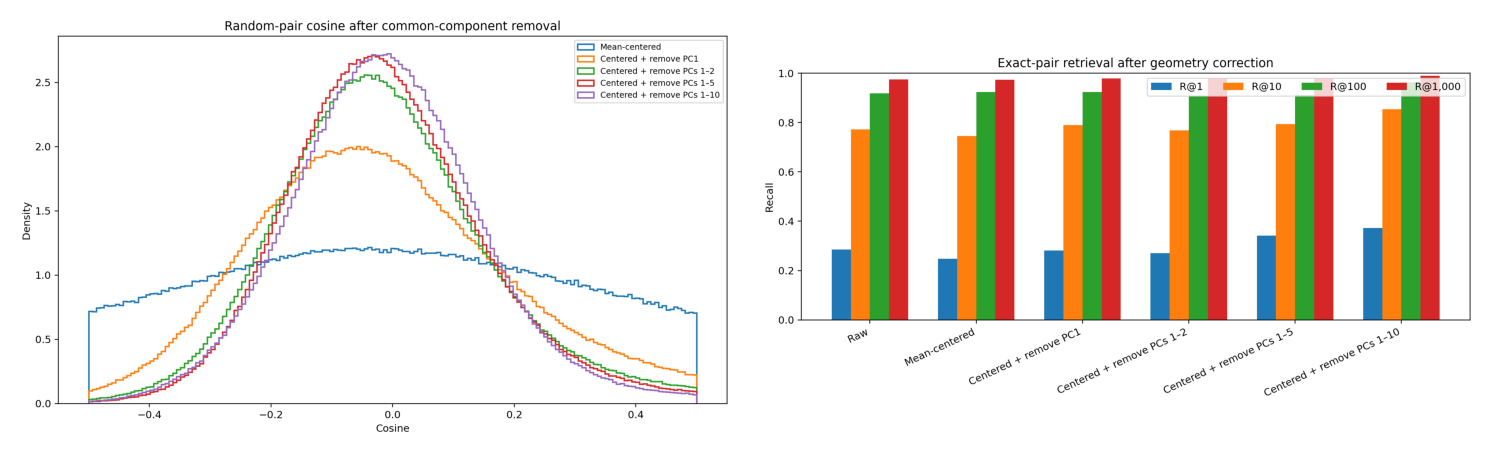

In [21]:
display(geometry_distributions[['representation','distribution','n','mean','median','sd','p5','p95','p99']].style.format({c:'{:.6f}' for c in ['mean','median','sd','p5','p95','p99']}).hide(axis='index'))
display(geometry_separation.style.format({c:'{:.6f}' for c in geometry_separation.columns if c != 'representation'}).hide(axis='index'))
display(geometry_retrieval.style.format({c:'{:.1%}' for c in ['r_at_1','r_at_10','r_at_100','r_at_1000','macro_r_at_10']}).format({'mrr':'{:.4f}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, ['pc_removal_cosine_distributions.png','retrieval_comparison.png']):
    ax.imshow(plt.imread(ANISO / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Biological preservation, density, and hubness

Centered-minus-PC10 also improves the available same-GSE, exact-source, and
limited blood/brain tissue metrics. Hubness is mixed: Top-1 concentration
falls, while Top-10 concentration rises. GSE234297 remains unusually dense
through PC2 but becomes less dense than other studies after PC5/PC10; common
components redistribute rather than uniformly eliminate local density.

representation,same_gse_top1,same_gse_top10,source_queries,source_p_at_1,source_p_at_10,tissue_queries,tissue_p_at_1,tissue_p_at_10
Raw,76.2%,91.1%,286,66.4%,49.5%,162,82.1%,68.8%
Mean-centered,75.3%,89.0%,286,67.1%,48.7%,162,83.3%,68.7%
Centered + remove PC1,79.0%,90.0%,286,73.4%,54.2%,162,90.7%,76.5%
Centered + remove PCs 1–2,79.2%,89.1%,286,72.0%,51.6%,162,85.2%,70.5%
Centered + remove PCs 1–5,79.2%,89.0%,286,70.3%,52.9%,162,88.3%,78.0%
Centered + remove PCs 1–10,84.3%,92.3%,286,73.8%,56.6%,162,88.9%,80.9%


representation,mean_query_density,sd_query_density,iqr_query_density,gse234297_mean_density,other_studies_mean_density,gse234297_minus_others
Raw,0.997758,0.002196,0.002144,0.999251,0.997244,0.002007
Mean-centered,0.982371,0.016086,0.015214,0.992892,0.978746,0.014146
Centered + remove PC1,0.964357,0.038860,0.021829,0.984043,0.957575,0.026468
Centered + remove PCs 1–2,0.961844,0.039772,0.021981,0.980177,0.955529,0.024648
Centered + remove PCs 1–5,0.950121,0.044397,0.040574,0.943578,0.952376,-0.008798
Centered + remove PCs 1–10,0.941612,0.050181,0.056367,0.927303,0.946542,-0.019239


representation,k,assignments,references_selected,maximum_nk,skewness,gini,top10_hubs_assignment_fraction
Raw,1,562,396,16,122.56,0.999424,14.06%
Raw,10,5620,1904,35,47.98,0.998179,4.88%
Mean-centered,1,562,383,15,108.32,0.999456,13.52%
Mean-centered,10,5620,1903,34,48.60,0.998181,5.04%
Centered + remove PC1,1,562,360,24,176.52,0.999512,17.44%
Centered + remove PC1,10,5620,1727,59,61.85,0.998410,6.39%
Centered + remove PCs 1–2,1,562,362,23,167.58,0.999509,17.62%
Centered + remove PCs 1–2,10,5620,1745,59,61.25,0.998388,6.33%
Centered + remove PCs 1–5,1,562,403,13,106.91,0.999407,13.88%
Centered + remove PCs 1–5,10,5620,1788,44,57.53,0.998334,6.28%


array([[[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       ...,

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1.

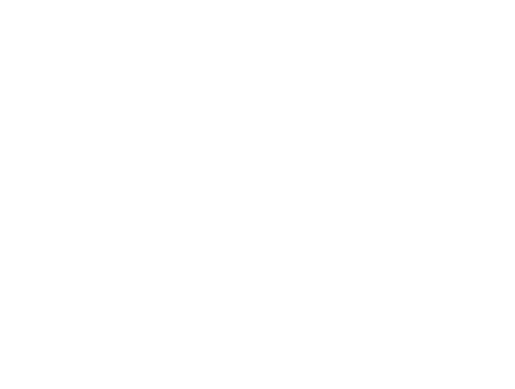

In [22]:
display(geometry_biology.style.format({c:'{:.1%}' for c in ['same_gse_top1','same_gse_top10','source_p_at_1','source_p_at_10','tissue_p_at_1','tissue_p_at_10']}).hide(axis='index'))
display(geometry_density.style.format({c:'{:.6f}' for c in geometry_density.columns if c != 'representation'}).hide(axis='index'))
display(geometry_hubness.style.format({'gini':'{:.6f}','top10_hubs_assignment_fraction':'{:.2%}','skewness':'{:.2f}'}).hide(axis='index'))
display(plt.imread(ANISO / 'figures/hubness_density_comparison.png')); plt.axis('off'); plt.show()

## Recommendation before GTEx

Retain raw cosine for interpretable absolute Bridge agreement. For technical
identity retrieval, carry centered-minus-PC10 forward as the leading frozen
reference-derived geometry, alongside raw cosine and NICDM/local scaling. A
future GTEx→ARCHS4 benchmark should freeze these three views before evaluation
and choose by biological and cross-study retrieval—not retune PC count on GTEx.
No representation learning or Bridge fine-tuning was performed.

# Literature-grounded post-processing

This extension freezes ABTT at D=10 and compares it with full-dimensional
BERT-style whitening. All means, PCs, and whitening parameters were fitted on
the 510,709 ARCHS4 references only and then applied unchanged to recount3. The
same retained two-million random-pair indices are used throughout. No component
count or whitening setting was tuned against recount3 retrieval.

method,distribution,n,mean,median,sd,p1,p5,p95,p99,p99.9
Raw cosine,random_ARCHS4_pairs,2000000,0.878748,0.912954,0.118144,0.354765,0.673433,0.967828,0.984401,0.996779
Raw cosine,exact_ARCHS4_recount3_pairs,562,0.997806,0.999218,0.003510,0.980139,0.991977,0.999658,0.999731,0.999822
Mean-centered,random_ARCHS4_pairs,2000000,0.006452,-0.002471,0.406919,-0.796157,-0.655725,0.692437,0.863638,0.968317
Mean-centered,exact_ARCHS4_recount3_pairs,562,0.985264,0.990891,0.024900,0.875941,0.948229,0.997122,0.997695,0.998385
ABTT D=10,random_ARCHS4_pairs,2000000,0.001168,-0.011327,0.180508,-0.366102,-0.258152,0.289961,0.644133,0.941849
ABTT D=10,exact_ARCHS4_recount3_pairs,562,0.951167,0.979425,0.069584,0.654025,0.799290,0.994749,0.996078,0.996459
Whitening,random_ARCHS4_pairs,2000000,0.000232,-0.002371,0.047161,-0.088852,-0.060149,0.060761,0.134576,0.476162
Whitening,exact_ARCHS4_recount3_pairs,562,0.791504,0.852378,0.152576,0.332970,0.443349,0.932360,0.939515,0.945453


dimensions_retained,eigenvalue_floor,eigenvalues_affected_by_floor,pre_min_eigenvalue,pre_max_eigenvalue,pre_condition_number,pre_participation_ratio,post_min_eigenvalue,post_max_eigenvalue,post_condition_number,post_participation_ratio,post_max_abs_eigenvalue_minus_one
512,1.05411e-11,0,3.54709e-06,10.5411,2.97177e+06,2.90742,0.995287,1.00616,1.01092,511.999,0.00615843


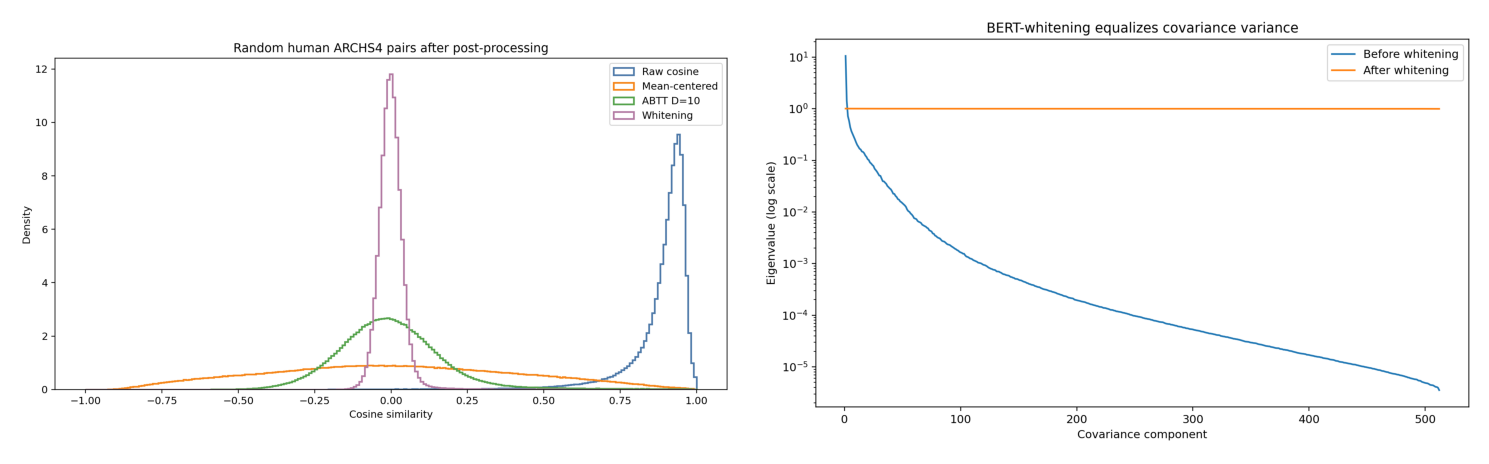

In [23]:
display(literature_distributions[['method','distribution','n','mean','median','sd','p1','p5','p95','p99','p99.9']].style.format({c:'{:.6f}' for c in ['mean','median','sd','p1','p5','p95','p99','p99.9']}).hide(axis='index'))
display(whitening_diagnostics.style.format('{:.6g}').hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, ['random_pair_distributions.png','whitening_covariance_spectrum.png']):
    ax.imshow(plt.imread(LIT / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Alignment and uniformity

Alignment is mean squared distance for the 562 normalized exact pairs; lower
is closer. Uniformity is `log E exp(-2||x-y||²)` over the fixed random pairs;
more negative is more uniform. Whitening sacrifices absolute pair closeness
but contracts the random distribution much more, producing the strongest
exact-versus-random AUROC. Uniformity is a diagnostic, not a sole objective.

method,alignment,uniformity,exact_pair_auroc,exact_median_random_percentile,exact_q1_random_percentile
Raw cosine,0.004388,-0.413519,0.999096,0.999936,0.999726
Mean-centered,0.029471,-2.773730,0.999411,0.999862,0.999730
ABTT D=10,0.097665,-3.606502,0.999055,0.999799,0.999085
Whitening,0.416992,-3.972797,0.999781,0.999962,0.999833


array([[[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       ...,

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]],

       [[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        ...,
        [1., 1., 1., 1.],
        [1., 1.

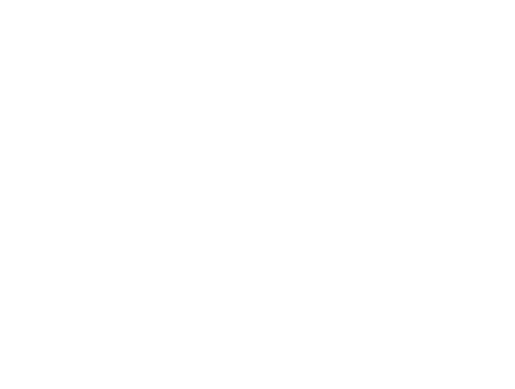

In [24]:
display(literature_diagnostics.style.format({c:'{:.6f}' for c in literature_diagnostics.columns if c != 'method'}).hide(axis='index'))
display(plt.imread(LIT / 'figures/alignment_uniformity.png')); plt.axis('off'); plt.show()

## Retrieval and study-macro comparison

Whitening is strongest for exact technical identity: R@1 46.62%, R@10 94.48%,
and study-macro R@10 94.12%. ABTT D=10 exactly reproduces the frozen prior
result (37.19%, 85.41%, and 84.46%). Retrieval-score corrections remain
separate: they change ranking criteria without defining a transformed Bridge
representation.

method,type,r_at_1,r_at_10,r_at_100,r_at_1000,mrr,macro_r_at_10,alignment,uniformity
Raw cosine,Representation,0.284698,0.772242,0.918149,0.975089,0.4764,0.759189,0.0044,-0.4135
Mean-centered,Representation,0.247331,0.745552,0.923488,0.973310,0.4467,0.665483,0.0295,-2.7737
ABTT D=10,Representation,0.371886,0.854093,0.962633,0.989324,0.5859,0.844555,0.0977,-3.6065
Whitening,Representation,0.466192,0.944840,0.991103,1.000000,0.6919,0.941209,0.4170,-3.9728
NICDM,Retrieval,0.304270,0.825623,0.943060,0.985765,0.5125,0.789611,nan,nan
Local Scaling,Retrieval,0.302491,0.816726,0.943060,0.985765,0.5119,0.786634,nan,nan
CSLS,Retrieval,0.293594,0.806050,0.941281,0.980427,0.5039,0.660072,nan,nan


method,macro_r_at_1,macro_r_at_5,macro_r_at_10,macro_r_at_100,macro_r_at_1000,macro_mrr
Raw cosine,0.329651,0.659714,0.759189,0.913273,0.969792,0.4886
Mean-centered,0.223042,0.617606,0.665483,0.923864,0.969618,0.4133
ABTT D=10,0.354085,0.802352,0.844555,0.929419,0.975000,0.5746
Whitening,0.376581,0.924274,0.941209,0.979167,1.000000,0.6457
NICDM,0.346812,0.716600,0.789611,0.928204,0.974653,0.5163
Local Scaling,0.342651,0.720826,0.786634,0.932197,0.974653,0.5155
CSLS,0.225035,0.605861,0.660072,0.838273,0.949479,0.4066


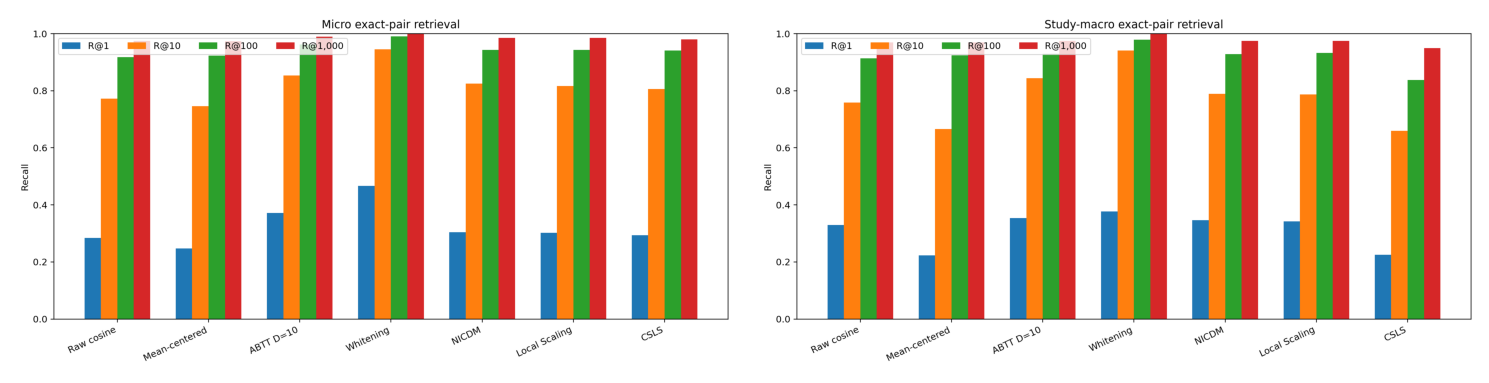

In [25]:
display(literature_main.style.format({c:'{:.1%}' for c in ['r_at_1','r_at_10','r_at_100','r_at_1000','macro_r_at_10']}).format({'mrr':'{:.4f}','alignment':'{:.4f}','uniformity':'{:.4f}'}).hide(axis='index'))
display(literature_macro[['method','macro_r_at_1','macro_r_at_5','macro_r_at_10','macro_r_at_100','macro_r_at_1000','macro_mrr']].style.format({c:'{:.1%}' for c in ['macro_r_at_1','macro_r_at_5','macro_r_at_10','macro_r_at_100','macro_r_at_1000']}).format({'macro_mrr':'{:.4f}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, ['retrieval_micro.png','retrieval_study_macro.png']):
    ax.imshow(plt.imread(LIT / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Biological preservation and hubness

ABTT has the strongest conservative source precision; whitening has the
strongest same-GSE metrics and limited tissue P@10. The tissue sensitivity is
blood/brain dominated. Whitening minimizes Top-1 hub concentration, whereas
NICDM/local scaling minimize Top-10 hub concentration. No method dominates
every objective.

method,same_gse_top1,same_gse_top10,source_queries,source_p_at_1,source_p_at_10,tissue_queries,tissue_p_at_1,tissue_p_at_10
Raw cosine,76.2%,91.1%,286.000000,66.4%,49.5%,162.000000,82.1%,68.8%
Mean-centered,75.3%,89.0%,286.000000,67.1%,48.7%,162.000000,83.3%,68.7%
ABTT D=10,84.3%,92.3%,286.000000,73.8%,56.6%,162.000000,88.9%,80.9%
Whitening,90.9%,97.5%,286.000000,66.8%,54.1%,162.000000,88.3%,84.1%
NICDM,74.2%,89.5%,286.000000,56.3%,36.8%,162.000000,76.5%,60.4%
Local Scaling,74.7%,89.3%,286.000000,57.3%,38.5%,162.000000,74.7%,62.2%
CSLS,71.9%,87.7%,286.000000,53.8%,37.2%,162.000000,75.3%,62.8%


method,k,assignments,references_selected,maximum_nk,skewness,gini,top10_hubs_assignment_fraction
Raw cosine,1,562,396,16,122.56,0.999424,14.06%
Raw cosine,10,5620,1904,35,47.91,0.998178,4.86%
NICDM,1,562,440,8,64.75,0.999304,9.07%
NICDM,10,5620,2383,20,35.21,0.997412,2.86%
Local Scaling,1,562,426,9,75.01,0.999342,9.96%
Local Scaling,10,5620,2280,19,34.95,0.997567,2.79%
CSLS,1,562,441,8,67.81,0.999302,9.25%
CSLS,10,5620,2509,22,37.74,0.997247,3.11%
Mean-centered,1,562,383,15,108.32,0.999456,13.52%
Mean-centered,10,5620,1903,34,48.60,0.998181,5.04%


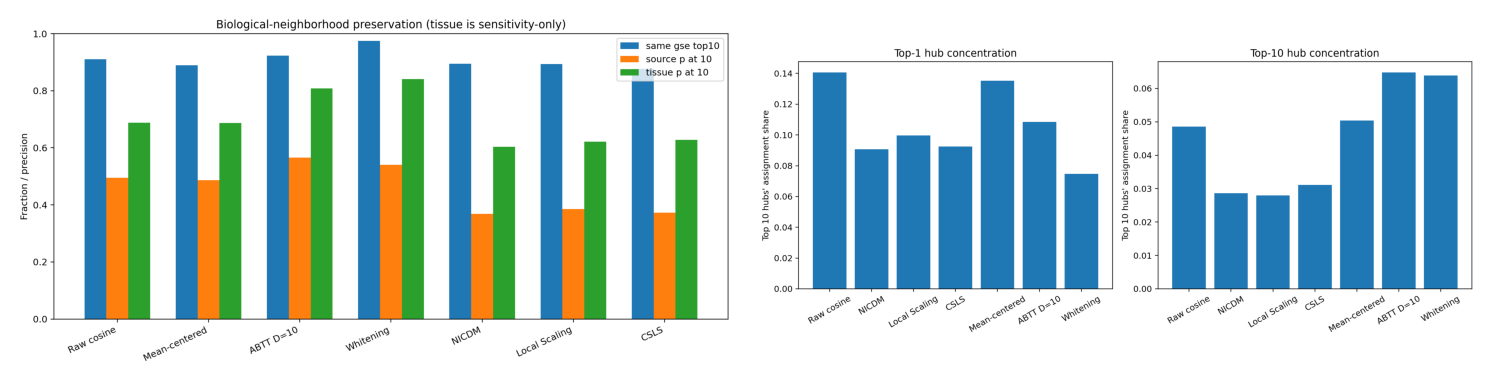

In [26]:
display(literature_biology.style.format({c:'{:.1%}' for c in ['same_gse_top1','same_gse_top10','source_p_at_1','source_p_at_10','tissue_p_at_1','tissue_p_at_10']}).hide(axis='index'))
display(literature_hubness.style.format({'top10_hubs_assignment_fraction':'{:.2%}','gini':'{:.6f}','skewness':'{:.2f}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, ['biological_preservation.png','hubness_comparison.png']):
    ax.imshow(plt.imread(LIT / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Frozen candidates for independent GTEx validation

Advance raw cosine, frozen ABTT D=10, full 512-D ARCHS4-fitted whitening,
NICDM k=10, and local scaling k=10. Raw cosine preserves direct Bridge-score
interpretability; ABTT is the source-label leader; whitening is the technical-
identity and isotropy leader; local corrections are retrieval-only comparators.
Mean-centering is diagnostic and CSLS remains supplemental. GTEx was not
examined, and no Bridge parameters or learned post-processors were trained.

# Independent GTEx → ARCHS4 tissue retrieval

This independent validation reuses 6,314 authoritative GTEx v11 samples and
their existing frozen Bridge embeddings. Frozen ARCHS4-derived transformations
are applied unchanged. Explicit GTEx-origin ARCHS4 records are excluded before
search, and no method is tuned on GTEx.

samples,unique_donors,broad_tissues,detailed_tissues,missing_broad_labels,missing_detailed_labels,largest_tissue_fraction,eligible_queries,eligible_harmonized_tissues
6314,937,17,18,0,0,13.0%,6064,13


references_before_exclusion,gtEx_origin_excluded,references_after_exclusion,confidently_labeled,unlabeled,coverage,labeled_tissues,largest_labeled_tissue_fraction,gtex_represented_labeled_references,gtex_represented_coverage_of_full_corpus,eligible_gtex_tissue_labeled_references,eligible_gtex_tissue_coverage_of_full_corpus
510709,333,510376,73338,437038,14.4%,18,65.2%,19526,3.83%,19507,3.82%


gtex_tissue,archs4_tissue,gtex_queries,references,gses,labeled_prevalence,eligible
adrenal,adrenal,250,19,4,0.026%,False
cerebellum,brain,236,2754,147,3.755%,True
cortex,brain,243,2754,147,3.755%,True
frontal cortex,brain,195,2754,147,3.755%,True
heart,heart,823,1110,51,1.514%,True
hippocampus,brain,181,2754,147,3.755%,True
liver,liver,222,5048,208,6.883%,True
lung,lung,532,2958,197,4.033%,True
mammary gland,breast,445,2208,123,3.011%,True
ovary,ovary,173,471,44,0.642%,True


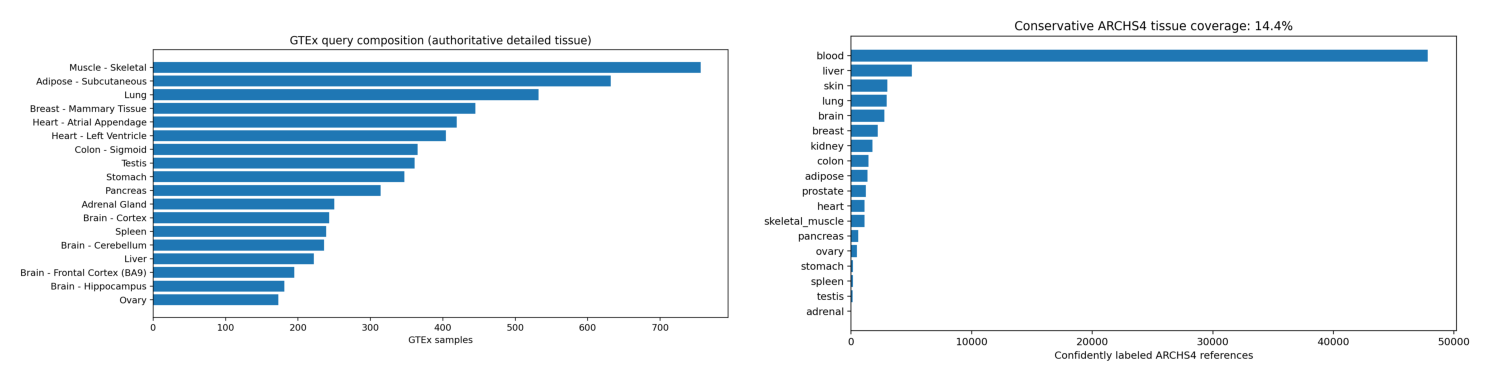

In [27]:
display(gtex_cohort.style.format({'largest_tissue_fraction':'{:.1%}'}).hide(axis='index'))
display(gtex_annotation.style.format({'coverage':'{:.1%}','largest_labeled_tissue_fraction':'{:.1%}','gtex_represented_coverage_of_full_corpus':'{:.2%}','eligible_gtex_tissue_coverage_of_full_corpus':'{:.2%}'}).hide(axis='index'))
display(gtex_harmonization.style.format({'labeled_prevalence':'{:.3%}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name in zip(axes, ['gtex_tissue_composition.png','archs4_tissue_coverage.png']):
    ax.imshow(plt.imread(GTEX / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Micro and tissue-macro retrieval

Annotated precision counts only confidently labeled retrieved references.
Hit@K uses all K positions; Unknown@K makes annotation missingness explicit.
Whitening leads tissue-macro P@10 (91.21%), ABTT narrowly leads micro annotated
P@10 (95.39%), and raw has the highest absolute Hit@10 (26.38%). Roughly
72–76% of Top-10 results are unlabeled under the conservative mapping.

method,annotated_precision,absolute_hit_rate,unknown_rate,annotated_precision_ci_low,annotated_precision_ci_high
Raw cosine,95.1%,26.4%,72.3%,94.8%,95.5%
ABTT D=10,95.4%,22.9%,76.0%,95.0%,95.7%
Whitening,95.0%,25.2%,73.5%,94.6%,95.3%
NICDM,92.3%,23.7%,74.3%,91.9%,92.7%
Local Scaling,92.5%,24.0%,74.0%,92.0%,92.9%
CSLS,93.8%,24.9%,73.4%,93.4%,94.1%


method,k,tissues,annotated_precision,absolute_hit_rate,unknown_rate,fold_enrichment
ABTT D=10,10,13,0.905998,0.224939,0.760776,141.1×
CSLS,10,13,0.839779,0.217918,0.764008,129.1×
Local Scaling,10,13,0.812035,0.208441,0.769524,121.7×
NICDM,10,13,0.806148,0.206189,0.771229,119.5×
Raw cosine,10,13,0.867303,0.231304,0.755108,136.6×
Whitening,10,13,0.912085,0.247709,0.736144,147.4×


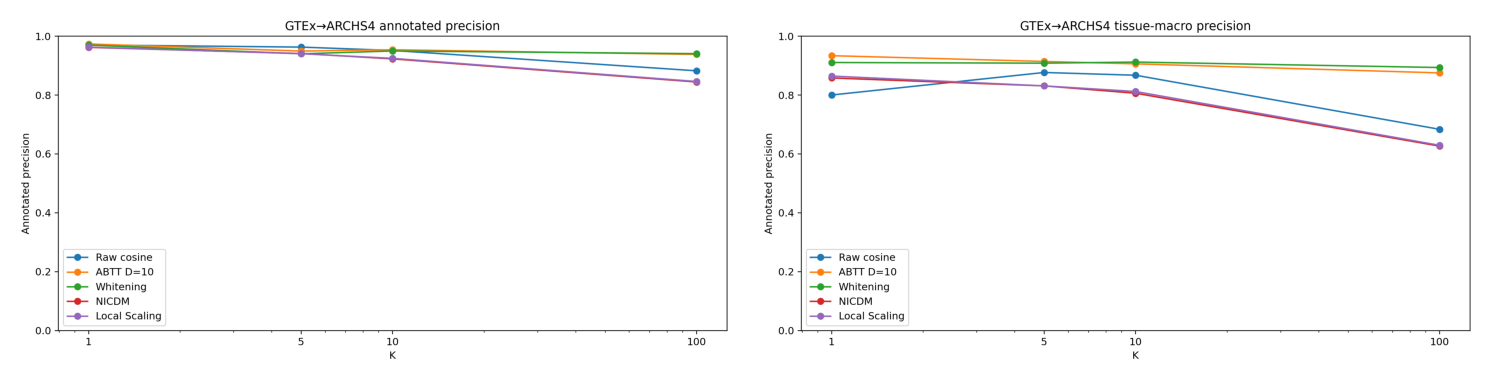

In [28]:
display(gtex_micro[gtex_micro.k.eq(10)][['method','annotated_precision','absolute_hit_rate','unknown_rate','annotated_precision_ci_low','annotated_precision_ci_high']].style.format({c:'{:.1%}' for c in ['annotated_precision','absolute_hit_rate','unknown_rate','annotated_precision_ci_low','annotated_precision_ci_high']}).hide(axis='index'))
display(gtex_macro[gtex_macro.k.eq(10)].style.format({c:'{:.1%}' for c in ['annotated_precision','absolute_hit_rate','unknown_rate']}).format({'fold_enrichment':'{:.1f}×'}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, ['micro_precision_by_k.png','tissue_macro_precision_by_k.png']):
    ax.imshow(plt.imread(GTEX / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Per-tissue behavior, confusions, and density

Brain and liver reach 100% annotated P@10 for all methods. Raw is weakest for
stomach and adipose; whitening substantially improves both, while breast and
spleen decline. Dominant labeled confusions include adipose↔breast and
pancreas↔stomach. Whitening exposes rather than removes between-tissue density
differences. Whole Blood is absent from this cached GTEx cohort.

tissue,gtex_queries,archs4_references,archs4_gses,raw_cosine_p_at_10,raw_cosine_unknown_at_10,abtt_d10_p_at_10,abtt_d10_unknown_at_10,whitening_p_at_10,whitening_unknown_at_10,nicdm_p_at_10,nicdm_unknown_at_10,local_scaling_p_at_10,local_scaling_unknown_at_10
adipose,632,1369,48,55.6%,86.5%,92.5%,82.1%,75.2%,83.6%,61.5%,82.4%,60.6%,82.1%
brain,855,2754,147,100.0%,70.3%,100.0%,81.5%,100.0%,82.6%,100.0%,69.8%,100.0%,69.8%
breast,445,2208,123,73.8%,78.4%,60.3%,82.6%,66.2%,83.0%,71.9%,74.5%,73.2%,74.0%
colon,365,1446,96,93.0%,98.1%,98.7%,93.8%,99.2%,93.3%,90.4%,98.0%,90.5%,98.0%
heart,823,1110,51,99.1%,73.5%,99.2%,71.5%,99.9%,70.1%,98.4%,74.2%,98.4%,74.1%
liver,222,5048,208,100.0%,58.9%,100.0%,58.0%,100.0%,58.3%,100.0%,56.5%,100.0%,57.3%
lung,532,2958,197,99.8%,43.2%,99.9%,63.5%,99.9%,59.2%,99.4%,49.9%,99.5%,48.8%
ovary,173,471,44,96.5%,83.7%,99.2%,78.4%,98.8%,76.2%,81.1%,86.2%,81.9%,86.3%
pancreas,314,606,57,85.1%,91.4%,100.0%,87.3%,100.0%,87.5%,54.8%,88.0%,55.4%,88.4%
skeletal_muscle,756,1110,41,99.9%,45.9%,99.3%,70.4%,98.9%,57.6%,99.8%,58.6%,99.8%,57.8%


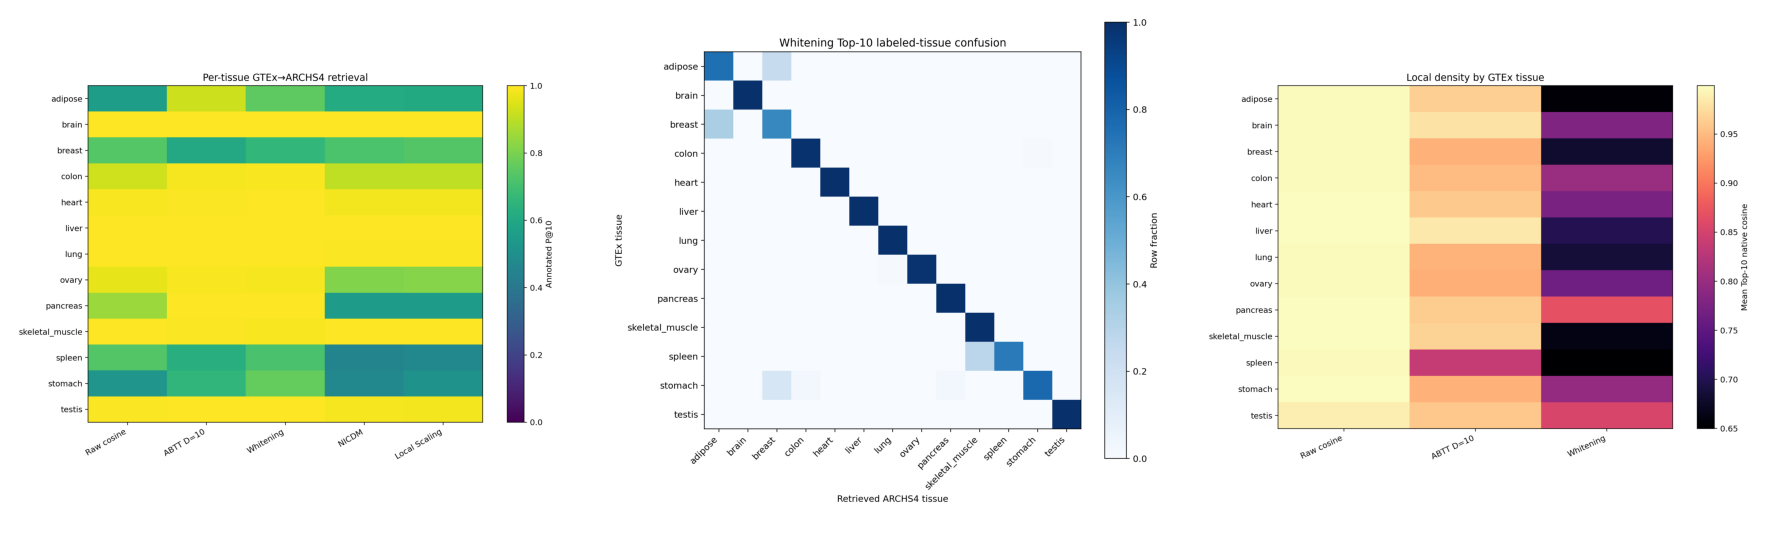

In [29]:
display(gtex_per_tissue.style.format({c:'{:.1%}' for c in gtex_per_tissue.columns if c.endswith('_p_at_10') or c.endswith('_unknown_at_10')}).hide(axis='index'))
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, name in zip(axes, ['per_tissue_p10_heatmap.png','tissue_confusion_whitening_top10.png','local_density_by_tissue.png']):
    ax.imshow(plt.imread(GTEX / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Controlled GTEx retrieval and technical-versus-biological comparison

After removing self and all same-donor samples, GTEx→GTEx tissue-macro P@10 is
90.61% raw, 93.35% ABTT, and 94.86% whitening. This agrees with the independent
ARCHS4 macro ordering. High raw cosine for both same- and different-tissue
neighbors confirms that decisions occur in the dense extreme tail.

method,recount3_exact_r_at_10,recount3_macro_r_at_10,gtex_archs4_tissue_p_at_10,gtex_tissue_macro_p_at_10,tissue_macro_enrichment_at_10,absolute_hit_at_10,unknown_at_10
Raw cosine,0.772242,0.759189,0.951472,0.867303,136.6×,0.263836,0.722708
ABTT D=10,0.854093,0.844555,0.953904,0.905998,141.1×,0.228644,0.760307
Whitening,0.944840,0.941209,0.949711,0.912085,147.4×,0.251633,0.735043
NICDM,0.825623,0.789611,0.922884,0.806148,119.5×,0.237220,0.742958
Local Scaling,0.816726,0.786634,0.924625,0.812035,121.7×,0.240122,0.740303


method,k,queries,micro_precision,tissue_macro_precision,tissues
Raw cosine,10,6064,92.3%,90.6%,16
ABTT D=10,10,6064,94.4%,93.4%,16
Whitening,10,6064,95.7%,94.9%,16


status,n,mean,median,p5,p95,median_random_pair_percentile
same_tissue,148003,0.996469,0.997540,0.991802,0.999574,99.937%
different_tissue,19736,0.994778,0.995583,0.991298,0.998375,99.843%
unknown,438661,0.993409,0.996129,0.969638,0.999351,99.870%


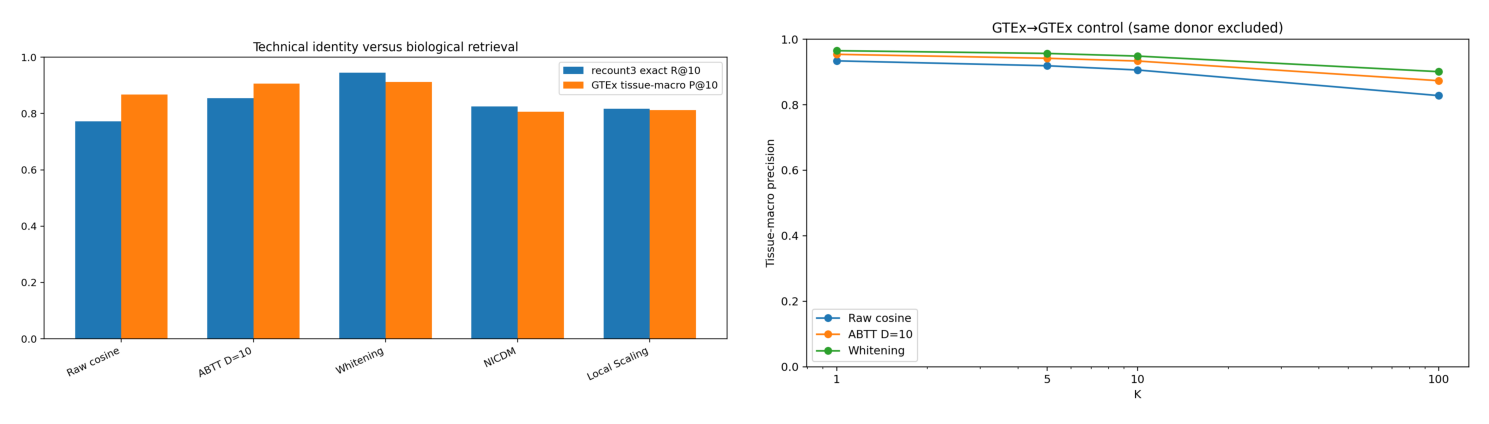

In [30]:
display(gtex_comparison.style.format({c:'{:.1%}' for c in ['recount3_exact_r_at_10','recount3_macro_r_at_10','gtex_archs4_tissue_p_at_10','gtex_tissue_macro_p_at_10','absolute_hit_at_10','unknown_at_10']}).format({'tissue_macro_enrichment_at_10':'{:.1f}×'}).hide(axis='index'))
display(gtex_control[gtex_control.k.eq(10)].style.format({'micro_precision':'{:.1%}','tissue_macro_precision':'{:.1%}'}).hide(axis='index'))
display(gtex_raw_scores.style.format({c:'{:.6f}' for c in ['mean','median','p5','p95']}).format({'median_random_pair_percentile':'{:.3%}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, ['technical_vs_biological.png','gtex_to_gtex_control.png']):
    ax.imshow(plt.imread(GTEX / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Recommendation and stop

Use whitening for exact identity and as the primary tissue-macro geometry.
Retain raw cosine for interpretable absolute similarity and labeled-hit yield,
and ABTT D=10 as a prespecified biological sensitivity. Advance all three
frozen representations to future cross-species testing; do not select only
whitening from human-only evidence. NICDM/local scaling remain baselines but
did not improve GTEx tissue retrieval. No cross-species analysis was run.

# Retrospective representation × metric controls

This section factors frozen representation, distance metric, and covariance
normalization on the unchanged 562-query × 510,709-reference recount3 task.
The full raw-expression control uses the exact 15,165-gene `log1p(TPM)`
contract reconstructed from existing ARCHS4 counts; all PCA parameters are fit
on ARCHS4 references only. Completed GTEx results are loaded but not rerun or
modified.

In [31]:
display(pd.DataFrame([control_assets]).T.rename(columns={0:'value'}))
display(control_pca.style.format({'variance_explained_512':'{:.2%}','eigenvalue_floor':'{:.3e}','participation_ratio':'{:.1f}'}).hide(axis='index'))

,value
archs4_h5,/home/walt/bridge-rna/data/archs4/human_gene_v...
h5_samples,888821
human_reference_samples,510709
expression_dataset,data/expression
source_dtype,uint32 counts
source_genes,67186
mapped_source_gene_rows,16556
canonical_genes,/home/walt/bridge-rna/data/ensembl/canonical_g...
canonical_genes_sha256,1dbe9a5753e5982b3ddb383f35e92ce5795c21fc054fff...
exon_lengths,/home/walt/bridge-rna/data/gencode/gencode_v49...


components,oversampling,power_iterations,solver,fit_samples,genes,variance_explained_512,eigenvalue_floor,affected_dimensions,participation_ratio
512,32,1,randomized range finder + thin QR + small SVD,510709,15165,87.76%,2.922e-09,0,14.2


## Retrieval and study-macro controls

Cosine/Pearson are similarities; Euclidean, Manhattan, and Canberra are
distances and are ranked in ascending order. Published raw-Bridge and
Bridge-whitened cosine results remain the authoritative rows in the summary.

In [32]:
cols=['representation','metric','r_at_1','r_at_10','r_at_100','r_at_1000','mrr','median_rank','runtime_seconds']
display(control_micro[cols].style.format({c:'{:.2%}' for c in ['r_at_1','r_at_10','r_at_100','r_at_1000']}).format({'mrr':'{:.4f}','runtime_seconds':'{:.1f}'}).hide(axis='index'))
display(control_macro[['representation','metric','macro_r_at_1','macro_r_at_10','macro_r_at_100','macro_r_at_1000','macro_mrr']].style.format({c:'{:.2%}' for c in ['macro_r_at_1','macro_r_at_10','macro_r_at_100','macro_r_at_1000']}).format({'macro_mrr':'{:.4f}'}).hide(axis='index'))

representation,metric,r_at_1,r_at_10,r_at_100,r_at_1000,mrr,median_rank,runtime_seconds
log1p(TPM),Cosine,0.576512,0.953737,0.967972,0.976868,0.7625,1.000000,18.5
log1p(TPM),Pearson,0.517794,0.960854,0.975089,0.987544,0.7374,1.000000,16.7
log1p(TPM),Euclidean,0.466192,0.934164,0.978648,0.989324,0.6980,2.000000,15.3
log1p(TPM),Manhattan,0.779359,0.950178,0.973310,0.989324,0.8627,1.000000,52.7
log1p(TPM),Canberra,0.782918,0.980427,0.989324,0.989324,0.8795,1.000000,348.0
PCA-512,Cosine,0.491103,0.916370,0.959075,0.989324,0.6891,2.000000,1.3
PCA-512,Euclidean,0.387900,0.916370,0.948399,0.989324,0.6330,2.000000,1.3
PCA-512,Manhattan,0.715302,0.923488,0.973310,0.987544,0.8122,1.000000,2.0
PCA-512,Canberra,0.660142,0.927046,0.985765,0.998221,0.7811,1.000000,12.9
PCA-512 whitened,Cosine,0.419929,0.921708,0.983986,1.000000,0.6595,2.000000,2.5


representation,metric,macro_r_at_1,macro_r_at_10,macro_r_at_100,macro_r_at_1000,macro_mrr
log1p(TPM),Cosine,0.552215,0.891477,0.923864,0.943750,0.7179
log1p(TPM),Pearson,0.542528,0.913258,0.937500,0.970833,0.7247
log1p(TPM),Euclidean,0.438621,0.902273,0.968182,0.975000,0.6644
log1p(TPM),Manhattan,0.704715,0.937879,0.961742,0.975000,0.8180
log1p(TPM),Canberra,0.740405,0.957197,0.975000,0.975000,0.8464
PCA-512,Cosine,0.482312,0.854609,0.905508,0.975000,0.6549
PCA-512,Euclidean,0.357776,0.849495,0.912326,0.975000,0.5849
PCA-512,Manhattan,0.686630,0.927257,0.969586,0.974826,0.7903
PCA-512,Canberra,0.643360,0.937689,0.970660,0.995833,0.7771
PCA-512 whitened,Cosine,0.463374,0.936206,0.977509,1.000000,0.6808


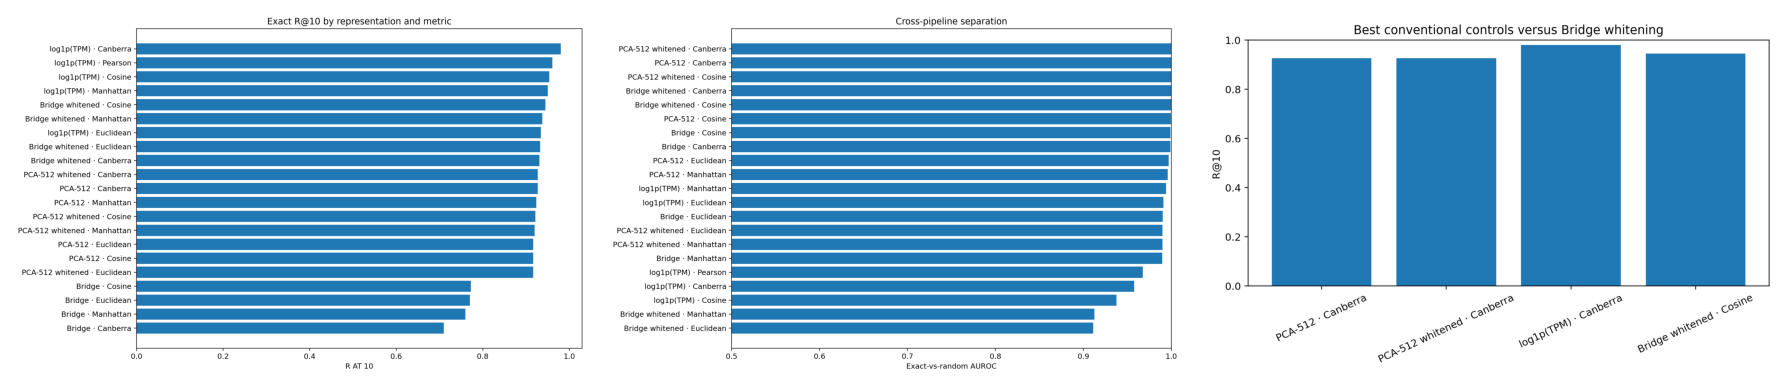

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, name in zip(axes, ['r_at_10.png','separation_auroc.png','best_baseline_vs_bridge_whitened.png']):
    ax.imshow(plt.imread(CTRL / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Attribution and limitations

The tables separate what can be recovered from ordinary expression geometry,
fixed 512-PC compression, PCA whitening, raw Bridge, and the already-frozen
Bridge whitening transform. Random-pair AUROC measures exact-pair separation
without conflating it with rank. The full-expression cache is derived and
ignored; no raw data, embeddings, GTEx analyses, or learned model parameters
were changed. See `REPORT.md` for the numerical attribution and storage/runtime
trade-offs.

# Frozen GTEx representation controls

The five conventional controls were fixed by the recount3 analysis before
this extension: expression Canberra/Pearson, PCA-512 Canberra, and PCA-white
cosine/Canberra. They use the unchanged 6,064-query, 13-harmonized-tissue,
510,376-reference benchmark. Existing Bridge rankings are reused exactly; no
GTEx fitting or method selection occurs here.

method,dimensions,recount3_exact_r_at_10,gtex_archs4_tissue_macro_p_at_10,gtex_gtex_tissue_macro_p_at_10
Expression Canberra,15165,98.04%,85.80%,95.32%
Expression Pearson,15165,96.09%,90.11%,96.12%
PCA-512 Canberra,512,92.70%,91.59%,95.28%
PCA-white cosine,512,92.17%,92.08%,95.42%
PCA-white Canberra,512,92.70%,91.59%,95.28%
Raw Bridge cosine,512,77.22%,86.73%,90.61%
Bridge ABTT D=10,502,85.41%,90.60%,93.35%
Bridge-white cosine,512,94.48%,91.21%,94.86%


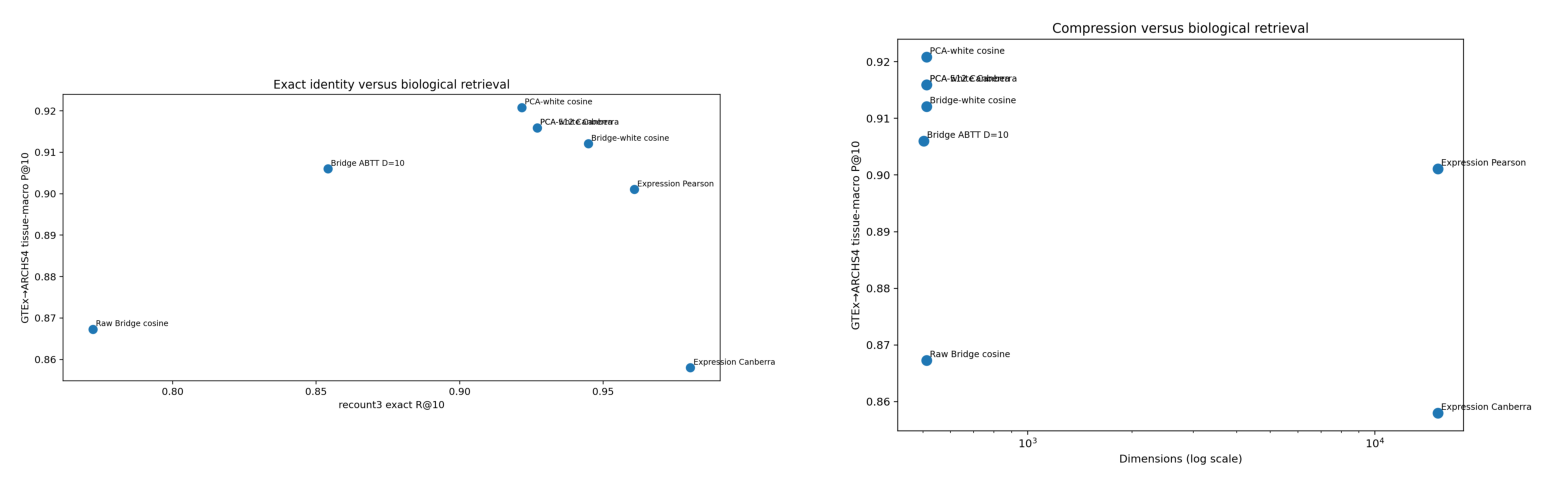

In [34]:
display(gctrl_identity.style.format({c:'{:.2%}' for c in ['recount3_exact_r_at_10','gtex_archs4_tissue_macro_p_at_10','gtex_gtex_tissue_macro_p_at_10']}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, name in zip(axes, ['identity_vs_biology.png','compression_vs_biology.png']):
    ax.imshow(plt.imread(GCTRL / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Primary and different-donor tissue retrieval

PCA-white cosine leads GTEx→ARCHS4 tissue-macro P@10 (92.08%), narrowly above
PCA Canberra (91.59%) and Bridge-white cosine (91.21%). In the fully labeled
different-donor control, expression Pearson leads (96.12%) and every frozen
conventional control exceeds Bridge whitening (94.86%). Unknown ARCHS4 labels
remain explicit and affect absolute hit yield.

method,k,tissues,annotated_precision,absolute_hit_rate,unknown_rate,fold_enrichment
Expression Canberra,10,13,0.858009,0.246414,0.729945,130.2×
Expression Pearson,10,13,0.901077,0.231245,0.748215,127.8×
PCA-512 Canberra,10,13,0.915918,0.253546,0.731210,151.9×
PCA-white Canberra,10,13,0.915918,0.253546,0.731210,151.9×
PCA-white cosine,10,13,0.920815,0.239771,0.744005,152.8×
Bridge ABTT D=10,10,13,0.905998,0.224939,0.760776,141.1×
Raw Bridge cosine,10,13,0.867303,0.231304,0.755108,136.6×
Bridge-white cosine,10,13,0.912085,0.247709,0.736144,147.4×


method,k,queries,micro_precision,tissue_macro_precision,tissues
Expression Canberra,10,6064,96.46%,95.32%,16
Expression Pearson,10,6064,96.90%,96.12%,16
PCA-512 Canberra,10,6064,96.33%,95.28%,16
PCA-white cosine,10,6064,96.46%,95.42%,16
PCA-white Canberra,10,6064,96.33%,95.28%,16
Raw Bridge cosine,10,6064,92.28%,90.61%,16
Bridge ABTT D=10,10,6064,94.39%,93.35%,16
Bridge-white cosine,10,6064,95.65%,94.86%,16


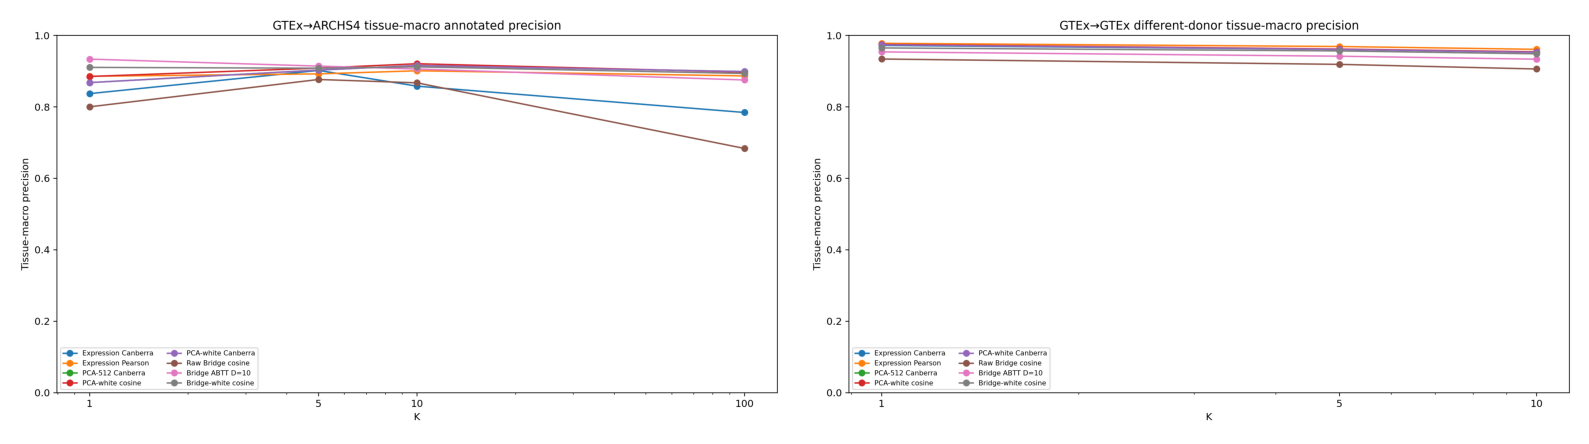

In [35]:
display(gctrl_macro[gctrl_macro.k.eq(10)].style.format({c:'{:.2%}' for c in ['annotated_precision','absolute_hit_rate','unknown_rate']}).format({'fold_enrichment':'{:.1f}×'}).hide(axis='index'))
display(gctrl_control[gctrl_control.k.eq(10)].style.format({'micro_precision':'{:.2%}','tissue_macro_precision':'{:.2%}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, name in zip(axes, ['gtex_archs4_macro_by_k.png','gtex_gtex_macro_by_k.png']):
    ax.imshow(plt.imread(GCTRL / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Tissue-specific errors and neighborhood overlap

Brain and liver are perfect across methods. Representation choice matters most
for adipose, breast, spleen, and stomach. Expression/PCA and Bridge whitening
share only about four to five of ten neighbors on average, so similar tissue
scores often arise from different sample neighborhoods.

method,Bridge ABTT D=10,Bridge-white cosine,Expression Canberra,Expression Pearson,PCA-512 Canberra,PCA-white Canberra,PCA-white cosine,Raw Bridge cosine
tissue,,,,,,,,
adipose,92.5%,75.2%,98.7%,99.8%,89.7%,89.7%,88.1%,55.6%
brain,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
breast,60.3%,66.2%,33.6%,19.9%,42.3%,42.3%,48.2%,73.8%
colon,98.7%,99.2%,96.8%,100.0%,100.0%,100.0%,99.7%,93.0%
heart,99.2%,99.9%,99.8%,99.8%,99.7%,99.7%,99.9%,99.1%
liver,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
lung,99.9%,99.9%,99.9%,99.9%,100.0%,100.0%,100.0%,99.8%
ovary,99.2%,98.8%,98.2%,99.3%,99.6%,99.6%,99.7%,96.5%
pancreas,100.0%,100.0%,94.9%,100.0%,100.0%,100.0%,100.0%,85.1%


,mean_shared,mean_jaccard,zero_overlap
method,,,
Expression Canberra,4.01,0.281,7.3%
Expression Pearson,4.59,0.332,5.0%
PCA-512 Canberra,4.37,0.309,4.5%


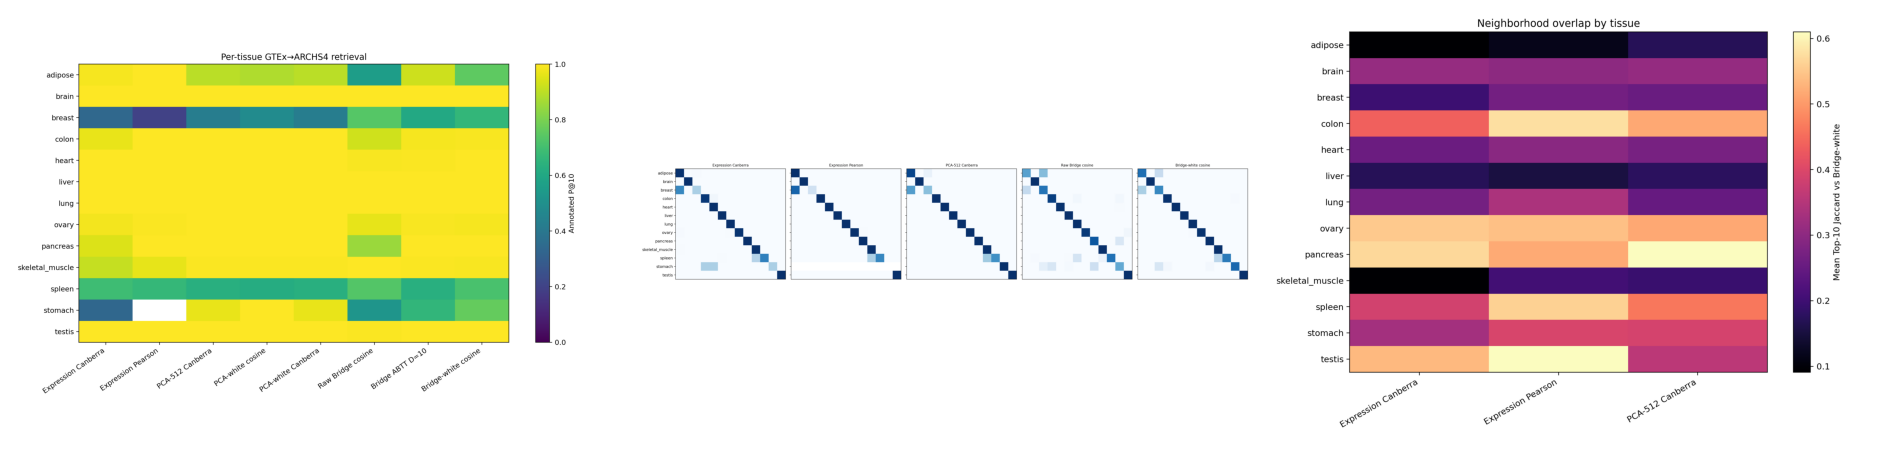

In [36]:
p10 = gctrl_tissue[gctrl_tissue.k.eq(10)].pivot(index='tissue', columns='method', values='annotated_precision')
display(p10.style.format('{:.1%}'))
display(gctrl_overlap.groupby('method').agg(mean_shared=('shared_neighbors','mean'),mean_jaccard=('jaccard','mean'),zero_overlap=('shared_neighbors',lambda x:(x==0).mean())).style.format({'mean_shared':'{:.2f}','mean_jaccard':'{:.3f}','zero_overlap':'{:.1%}'}))
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, name in zip(axes, ['per_tissue_p10.png','tissue_confusion_comparison.png','neighborhood_overlap.png']):
    ax.imshow(plt.imread(GCTRL / 'figures' / name)); ax.axis('off')
plt.tight_layout(); plt.show()

## Conclusion and stop

Bridge does not outperform the frozen conventional controls on this tissue
task. Full expression remains strongest for exact identity; expression
Pearson wins the fully labeled GTEx control; and matched-dimensional PCA
slightly leads Bridge whitening on GTEx→ARCHS4 tissue-macro retrieval. Bridge
whitening still exposes useful biology in a compact learned representation,
but broad human-tissue organization is largely explainable by linear
transcriptomic structure. No cross-species or perturbation analysis was run.

# Exploratory contextual-metadata audit

The union of cached Top-100 hits is deduplicated before annotation: 24,938 GSMs
are each classified once using frozen explicit-evidence rules over GEO source,
title, and characteristics. Conflicts and missing evidence remain unknown.
No embedding or retrieval calculation is repeated. No cached corpus-wide GSE
title/summary/design asset was available.

In [37]:
display(context_coverage.style.format({'fraction':'{:.2%}'}).hide(axis='index'))
display(context_confidence.style.format({'fraction':'{:.2%}'}).hide(axis='index'))

axis,label,samples,fraction
state,unknown,16958,68.00%
state,tumor_cancer,3694,14.81%
state,control,2265,9.08%
state,normal_healthy,1983,7.95%
state,treated,38,0.15%
material,unknown,20502,82.21%
material,primary_tissue,4062,16.29%
material,cell_line,374,1.50%


axis,status,samples,fraction
state,none,15690,62.92%
state,high,7980,32.00%
state,conflict,1268,5.08%
material,none,20493,82.18%
material,high,4436,17.79%
material,conflict,9,0.04%


## Tissue-conditioned context

GTEx explicitly supports a primary-tissue query context. It does not provide
sample-level healthy-state evidence, so `normal_healthy` is a descriptive proxy
rather than authoritative agreement. Precision uses confidently annotated hits;
unknown fractions remain explicit and are the dominant limitation.

In [38]:
ctx = context_metrics[(context_metrics.k == 10) & context_metrics.tissue_conditioned]
display(ctx[['method','axis','retrieved_hits','confident_hits','agreement_precision','absolute_agreement_rate','unknown_fraction']].style.format({c:'{:.2%}' for c in ['agreement_precision','absolute_agreement_rate','unknown_fraction']}).hide(axis='index'))

method,axis,retrieved_hits,confident_hits,agreement_precision,absolute_agreement_rate,unknown_fraction
Expression Pearson,material,14313,673,79.94%,3.76%,95.30%
Expression Pearson,state_proxy,14313,3626,60.34%,15.29%,74.67%
Expression Canberra,material,15942,998,76.65%,4.80%,93.74%
Expression Canberra,state_proxy,15942,2851,74.57%,13.34%,82.12%
PCA-512 Canberra,material,15656,261,65.90%,1.10%,98.33%
PCA-512 Canberra,state_proxy,15656,3382,67.30%,14.54%,78.40%
PCA-white cosine,material,14970,223,70.85%,1.06%,98.51%
PCA-white cosine,state_proxy,14970,3563,61.58%,14.66%,76.20%
Raw Bridge cosine,material,15999,1154,87.26%,6.29%,92.79%
Raw Bridge cosine,state_proxy,15999,2567,67.94%,10.90%,83.96%


## Auditable examples and conclusion

Examples use the lowest query index whose Top-1 is tissue-matched and has at
least one confident context annotation. Original metadata and the exact matched
rule/evidence are retained in the saved table. Coverage is too sparse to support
disease-state claims or method tuning; this remains a high-precision exploratory
annotation layer.

In [39]:
cols=['method','gtex_sample','query_tissue','rank','gsm','gse','retrieved_tissue','state','material','source_name_ch1','title','state_evidence','material_evidence']
display(context_examples[context_examples['rank'] <= 3][cols].head(18))

,method,gtex_sample,query_tissue,rank,gsm,gse,retrieved_tissue,state,material,source_name_ch1,title,state_evidence,material_evidence
0,Expression Pearson,GTEX-117XS-3126-SM-5GIDP,brain,1,GSM1580884,GSE64810,brain,normal_healthy,unknown,brain,C_0018,normal_terms|characteristics_ch1| prefrontal c...,NaN
1,Expression Pearson,GTEX-117XS-3126-SM-5GIDP,brain,2,GSM1679663,GSE68719,NaN,unknown,primary_tissue,BA9 prefrontal cortex,C_0018 [reanalysis of GSM1580884],NaN,primary_tissue_terms|characteristics_ch1|: bra...
2,Expression Pearson,GTEX-117XS-3126-SM-5GIDP,brain,3,GSM3713477,GSE129473,NaN,unknown,unknown,BA9 prefrontal cortex,C_0018 (re-analyzed),NaN,NaN
5,Expression Canberra,GTEX-11EI6-2926-SM-5985U,brain,1,GSM1642314,GSE67196,brain,normal_healthy,unknown,brain,24_cereb,normal_terms|characteristics_ch1|tissue: Cereb...,NaN
6,Expression Canberra,GTEX-11EI6-2926-SM-5985U,brain,2,GSM1642292,GSE67196,brain,unknown,unknown,brain,7_cereb_b,NaN,NaN
7,Expression Canberra,GTEX-11EI6-2926-SM-5985U,brain,3,GSM7807650,GSE244124,NaN,unknown,unknown,NORMAL-Cerebellum,NORMAL-Cerebellum-1292-X Female,tumor_cancer: malignant_terms|characteristics_...,NaN
10,PCA-512 Canberra,GTEX-117XS-3126-SM-5GIDP,brain,1,GSM1580884,GSE64810,brain,normal_healthy,unknown,brain,C_0018,normal_terms|characteristics_ch1| prefrontal c...,NaN
11,PCA-512 Canberra,GTEX-117XS-3126-SM-5GIDP,brain,2,GSM1679663,GSE68719,NaN,unknown,primary_tissue,BA9 prefrontal cortex,C_0018 [reanalysis of GSM1580884],NaN,primary_tissue_terms|characteristics_ch1|: bra...
12,PCA-512 Canberra,GTEX-117XS-3126-SM-5GIDP,brain,3,GSM3713477,GSE129473,NaN,unknown,unknown,BA9 prefrontal cortex,C_0018 (re-analyzed),NaN,NaN
15,PCA-white cosine,GTEX-13X6J-2926-SM-7EPGP,brain,1,GSM1580884,GSE64810,brain,normal_healthy,unknown,brain,C_0018,normal_terms|characteristics_ch1| prefrontal c...,NaN
